# D2-to-D3 TDI/IAG CLR heatmap for selected D3 programs

This notebook recreates the three-row heatmap using:

- **Control / Control** as a zero reference row;
- **TDI**: `D2_LM+TDI->D3_AE+TDI` vs matched `D3_AE` control;
- **IAG**: `D2_LM+IAG->D3_AE+IAG` vs matched `D3_AE` control.

Program columns are zero-based and ordered as:

```text
P2, P3, P8, P11, P33, P34
```

Labels are taken from the first annotation table in *Program annotation notes (Kyle+Hunter).pdf*:

- P2 - Artery endothelium 1
- P3 - Endothelial function 1
- P8 - Artery endothelium 2
- P11 - Endothelial function 2
- P33 - Anterior-like mesoderm
- P34 - Mesenchyme, YAP/TAZ-induced

CLR is applied at the **cell level across all 50 projected programs**, then averaged per biological sample. Treatment effects and statistics are calculated from matched biological-replicate sample means.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "figure.dpi": 160,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",  # keep text editable in Illustrator
})

# ------------------------------------------------------------------
# Paths
# ------------------------------------------------------------------
BASE = Path("/scratch/users/edtng/20260325_Hippo_timecourse")
PROJ_DIR = BASE / "perturbseq_cNMF_projection"
H5AD_PATH = PROJ_DIR / "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"

OUT_DIR = PROJ_DIR / "D2toD3_CLR_heatmap_P2_P3_P8_P11_P33_P34"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SCORE_KEY = "X_perturbseq_cNMF_usage"
SAMPLE_COL = "sample_name"

# ------------------------------------------------------------------
# CLR settings
# ------------------------------------------------------------------
# programDE-style structure: floor -> renormalize -> log -> center.
CLR_EPS = 1e-6
CLR_LOG_BASE = 2

# ------------------------------------------------------------------
# Requested programs and PDF-derived annotation labels
# ------------------------------------------------------------------
SELECTED_PROGRAMS = ["P2", "P3", "P8", "P11", "P33", "P34"]
PROGRAM_LABELS = {
    "P2": "P2\nArtery endothelium 1",
    "P3": "P3\nEndothelial function 1",
    "P8": "P8\nArtery endothelium 2",
    "P11": "P11\nEndothelial function 2",
    "P33": "P33\nAnterior-like mesoderm",
    "P34": "P34\nMesenchyme, YAP/TAZ-induced",
}

CONTROL_CONDITION = "D3_AE"
TREATED_CONDITIONS = {
    "TDI": "D2_LM+TDI->D3_AE+TDI",
    "IAG": "D2_LM+IAG->D3_AE+IAG",
}
ROW_ORDER = ["Control", "TDI", "IAG"]

# ------------------------------------------------------------------
# Statistical display
# ------------------------------------------------------------------
# Paired t-test across matched biological replicate means.
# Stars use BH-adjusted q-values across 2 treatments x 6 programs.
STAR_BY = "padj_bh"  # alternatives: "pvalue" or None

print("H5AD_PATH:", H5AD_PATH)
print("exists:", H5AD_PATH.exists())
print("OUT_DIR:", OUT_DIR)
print("programs:", SELECTED_PROGRAMS)

H5AD_PATH: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad
exists: True
OUT_DIR: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/D2toD3_CLR_heatmap_P2_P3_P8_P11_P33_P34
programs: ['P2', 'P3', 'P8', 'P11', 'P33', 'P34']


## QC cutoffs and helper functions

In [2]:
# Same condition-specific QC cutoffs used in the earlier time-course analysis.
cond_pct_ribo_cutoffs = {
    'D0_hPSC': 2.4,
    'D1_MPS': 2.3,
    'D1_MPS+TDI': 2.5,
    'D1_MPS+IAG': 2.2,
    'D1.33_LM': 1.9,
    'D1.33_LM+TDI': 2.1,
    'D1.33_LM+IAG': 2.2,
    'D1.67_LM': 2.0,
    'D1.67_LM+TDI': 2.2,
    'D1.67_LM+IAG': 1.9,
    'D2_LM': 2.0,
    'D2_LM+TDI': 2.4,
    'D2_LM+IAG': 1.9,
    'D3_AE': 1.0,
    'D3_AE+TDI': 2.0,
    'D3_AE+IAG': 1.0,
    'D2_LM+TDI->D3_AE+TDI': 2.5,
    'D2_LM+IAG->D3_AE+IAG': 1.0,
}

cond_pct_mt_cutoffs = {
    'D0_hPSC': 5.5,
    'D1_MPS': 3.0,
    'D1_MPS+TDI': 3.0,
    'D1_MPS+IAG': 4.0,
    'D1.33_LM': 3.5,
    'D1.33_LM+TDI': 3.75,
    'D1.33_LM+IAG': 5.0,
    'D1.67_LM': 4.0,
    'D1.67_LM+TDI': 5.5,
    'D1.67_LM+IAG': 3.5,
    'D2_LM': 6.5,
    'D2_LM+TDI': 8.0,
    'D2_LM+IAG': 3.5,
    'D3_AE': 3.25,
    'D3_AE+TDI': 7.0,
    'D3_AE+IAG': 3.75,
    'D2_LM+TDI->D3_AE+TDI': 7.0,
    'D2_LM+IAG->D3_AE+IAG': 3.75,
}


def parse_sample_name(sample_name):
    """Return (condition, replicate_number) from a sample such as D3_AE_rep2."""
    sample_name = str(sample_name)
    match = re.match(r"^(.*)_rep(\d+)$", sample_name)
    if match is None:
        raise ValueError(f"Could not parse sample_name: {sample_name!r}")
    return match.group(1), int(match.group(2))


def clr_transform_rows(compositions, eps=1e-6, log_base=2):
    """CLR transform cells x programs after flooring and row renormalization."""
    x = np.asarray(compositions, dtype=np.float64)
    if x.ndim != 2:
        raise ValueError(f"Expected a 2D usage matrix, got shape {x.shape}")
    if np.any(x < 0):
        raise ValueError("CLR input contains negative values.")

    row_sums = x.sum(axis=1, keepdims=True)
    x = np.divide(x, row_sums, out=np.zeros_like(x), where=row_sums > 0)
    x = np.maximum(x, eps)
    x = x / x.sum(axis=1, keepdims=True)

    if log_base == 2:
        log_x = np.log2(x)
    elif log_base in (None, "natural", "e"):
        log_x = np.log(x)
    else:
        raise ValueError("log_base must be 2 or 'natural'.")

    clr = log_x - log_x.mean(axis=1, keepdims=True)
    return clr.astype(np.float32)


def bh_adjust(pvalues):
    """Benjamini-Hochberg correction, preserving NaN positions."""
    pvalues = np.asarray(pvalues, dtype=float)
    out = np.full(pvalues.shape, np.nan, dtype=float)
    valid = np.isfinite(pvalues)
    p = pvalues[valid]
    if len(p) == 0:
        return out
    order = np.argsort(p)
    ranked = p[order]
    n = len(ranked)
    adjusted = ranked * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)
    back = np.empty_like(adjusted)
    back[order] = adjusted
    out[valid] = back
    return out


def significance_stars(value):
    if value is None or not np.isfinite(value):
        return ""
    if value < 0.001:
        return "***"
    if value < 0.01:
        return "**"
    if value < 0.05:
        return "*"
    return ""

## Load projected usage, apply QC, and compute sample-level CLR means

The large RNA expression matrix stays backed on disk. Only `obs` and the 50-column projected usage matrix are loaded into memory.

In [3]:
adata = sc.read_h5ad(H5AD_PATH, backed="r")
obs = adata.obs.copy()
usage = np.asarray(adata.obsm[SCORE_KEY])

projection_meta = adata.uns.get("perturbseq_cNMF_projection", {})
program_names = [str(x) for x in projection_meta.get("program_names", [])]
if len(program_names) != usage.shape[1]:
    program_names = [f"P{i}" for i in range(usage.shape[1])]

print("usage shape:", usage.shape)
print("first/last programs:", program_names[:5], program_names[-5:])

missing_programs = [p for p in SELECTED_PROGRAMS if p not in program_names]
if missing_programs:
    raise ValueError(f"Selected programs missing from saved projection: {missing_programs}")

if SAMPLE_COL not in obs.columns:
    raise KeyError(f"{SAMPLE_COL!r} not found in adata.obs")
for col in ["pct_counts_mt", "pct_counts_ribo"]:
    if col not in obs.columns:
        raise KeyError(f"{col!r} not found in adata.obs")

parsed = obs[SAMPLE_COL].astype(str).map(parse_sample_name)
obs["condition_for_heatmap"] = [x[0] for x in parsed]
obs["replicate_for_heatmap"] = [x[1] for x in parsed]
obs["pct_counts_mt"] = pd.to_numeric(obs["pct_counts_mt"], errors="coerce")
obs["pct_counts_ribo"] = pd.to_numeric(obs["pct_counts_ribo"], errors="coerce")

# Keep only the three conditions needed for this heatmap before CLR aggregation.
needed_conditions = {CONTROL_CONDITION, *TREATED_CONDITIONS.values()}
condition_mask = obs["condition_for_heatmap"].isin(needed_conditions).to_numpy()

qc_keep = np.zeros(obs.shape[0], dtype=bool)
qc_records = []
for condition in needed_conditions:
    cond_mask = (obs["condition_for_heatmap"].to_numpy() == condition)
    fail_mt = cond_mask & (obs["pct_counts_mt"].to_numpy() >= cond_pct_mt_cutoffs[condition])
    fail_ribo = cond_mask & (obs["pct_counts_ribo"].to_numpy() <= cond_pct_ribo_cutoffs[condition])
    fail_any = fail_mt | fail_ribo
    keep_cond = cond_mask & ~fail_any
    qc_keep |= keep_cond
    qc_records.append({
        "condition": condition,
        "n_before": int(cond_mask.sum()),
        "n_fail_mt": int(fail_mt.sum()),
        "n_fail_low_ribo": int(fail_ribo.sum()),
        "n_removed_any": int(fail_any.sum()),
        "n_after": int(keep_cond.sum()),
        "pct_counts_mt_cutoff": cond_pct_mt_cutoffs[condition],
        "pct_counts_ribo_cutoff": cond_pct_ribo_cutoffs[condition],
    })

qc_summary = pd.DataFrame(qc_records).sort_values("condition")
qc_summary.to_csv(OUT_DIR / "QC_summary_selected_D2toD3_conditions.tsv", sep="\t", index=False)
display(qc_summary)

obs_f = obs.loc[qc_keep].copy()
usage_f = usage[qc_keep, :]
print(f"Cells retained for heatmap: {usage_f.shape[0]:,}")

# Cell-level CLR across all projected programs.
clr_f = clr_transform_rows(usage_f, eps=CLR_EPS, log_base=CLR_LOG_BASE)
print("CLR shape:", clr_f.shape)
print("Max absolute row mean after CLR:", float(np.max(np.abs(clr_f.mean(axis=1)))))

clr_df = pd.DataFrame(clr_f, index=obs_f.index.astype(str), columns=program_names)
clr_df[SAMPLE_COL] = obs_f[SAMPLE_COL].astype(str).to_numpy()
clr_df["condition"] = obs_f["condition_for_heatmap"].astype(str).to_numpy()
clr_df["replicate"] = obs_f["replicate_for_heatmap"].astype(int).to_numpy()

sample_clr = clr_df.groupby(SAMPLE_COL, observed=True)[program_names].mean()
sample_meta = (
    clr_df[[SAMPLE_COL, "condition", "replicate"]]
    .drop_duplicates(SAMPLE_COL)
    .set_index(SAMPLE_COL)
    .loc[sample_clr.index]
)

sample_clr.to_csv(OUT_DIR / "sample_mean_log2CLR_projected_program_usage.tsv", sep="\t")
sample_meta.to_csv(OUT_DIR / "sample_metadata_for_CLR_heatmap.tsv", sep="\t")

display(sample_meta.sort_values(["condition", "replicate"]))

adata.file.close()

usage shape: (212891, 50)
first/last programs: ['P0', 'P1', 'P2', 'P3', 'P4'] ['P45', 'P46', 'P47', 'P48', 'P49']


,condition,n_before,n_fail_mt,n_fail_low_ribo,n_removed_any,n_after,pct_counts_mt_cutoff,pct_counts_ribo_cutoff
0,D2_LM+IAG->D3_AE+IAG,5307,2622,2721,2820,2487,3.75,1.0
1,D2_LM+TDI->D3_AE+TDI,15140,1373,5530,5587,9553,7.00,2.5
2,D3_AE,8704,5776,4148,6017,2687,3.25,1.0


Cells retained for heatmap: 14,727
CLR shape: (14727, 50)
Max absolute row mean after CLR: 3.4332276754867053e-07


,condition,replicate
sample_name,,
D2_LM+IAG->D3_AE+IAG_rep1,D2_LM+IAG->D3_AE+IAG,1
D2_LM+IAG->D3_AE+IAG_rep2,D2_LM+IAG->D3_AE+IAG,2
D2_LM+IAG->D3_AE+IAG_rep3,D2_LM+IAG->D3_AE+IAG,3
D2_LM+TDI->D3_AE+TDI_rep1,D2_LM+TDI->D3_AE+TDI,1
D2_LM+TDI->D3_AE+TDI_rep2,D2_LM+TDI->D3_AE+TDI,2
D2_LM+TDI->D3_AE+TDI_rep3,D2_LM+TDI->D3_AE+TDI,3
D3_AE_rep1,D3_AE,1
D3_AE_rep2,D3_AE,2
D3_AE_rep3,D3_AE,3


## Matched-replicate effects and paired statistical tests

For each treatment and program:

```text
rep1 effect = treated_rep1 CLR - control_rep1 CLR
rep2 effect = treated_rep2 CLR - control_rep2 CLR
rep3 effect = treated_rep3 CLR - control_rep3 CLR
```

A two-sided paired t-test is applied to the matched sample-level CLR values. Benjamini-Hochberg correction is applied across all 12 treatment-program tests.

In [4]:
effect_records = []
paired_records = []

control_meta = sample_meta[sample_meta["condition"] == CONTROL_CONDITION]
control_by_rep = control_meta.reset_index().set_index("replicate")[SAMPLE_COL].to_dict()

for treatment, treated_condition in TREATED_CONDITIONS.items():
    treated_meta = sample_meta[sample_meta["condition"] == treated_condition]
    treated_by_rep = treated_meta.reset_index().set_index("replicate")[SAMPLE_COL].to_dict()
    matched_reps = sorted(set(control_by_rep).intersection(treated_by_rep))
    print(treatment, treated_condition, "matched reps:", matched_reps)

    if len(matched_reps) < 2:
        raise ValueError(f"Fewer than two matched replicates for {treatment}: {matched_reps}")

    for program in SELECTED_PROGRAMS:
        control_values = np.array([sample_clr.loc[control_by_rep[r], program] for r in matched_reps], dtype=float)
        treated_values = np.array([sample_clr.loc[treated_by_rep[r], program] for r in matched_reps], dtype=float)
        paired_diff = treated_values - control_values

        t_stat, pvalue = stats.ttest_rel(treated_values, control_values, nan_policy="omit")

        effect_records.append({
            "treatment": treatment,
            "treated_condition": treated_condition,
            "control_condition": CONTROL_CONDITION,
            "program": program,
            "program_label": PROGRAM_LABELS[program].replace("\n", " - "),
            "n_matched_pairs": len(matched_reps),
            "mean_control_clr": float(control_values.mean()),
            "mean_treated_clr": float(treated_values.mean()),
            "mean_diff_clr": float(paired_diff.mean()),
            "sd_diff_clr": float(paired_diff.std(ddof=1)) if len(paired_diff) > 1 else np.nan,
            "t_statistic": float(t_stat),
            "pvalue": float(pvalue),
            "n_positive_diffs": int((paired_diff > 0).sum()),
            "n_negative_diffs": int((paired_diff < 0).sum()),
        })

        for rep, control_value, treated_value, diff in zip(matched_reps, control_values, treated_values, paired_diff):
            paired_records.append({
                "treatment": treatment,
                "treated_condition": treated_condition,
                "control_condition": CONTROL_CONDITION,
                "program": program,
                "replicate": rep,
                "control_sample": control_by_rep[rep],
                "treated_sample": treated_by_rep[rep],
                "control_clr": control_value,
                "treated_clr": treated_value,
                "paired_diff_clr": diff,
            })

effects = pd.DataFrame(effect_records)
effects["padj_bh"] = bh_adjust(effects["pvalue"].to_numpy())
paired_values = pd.DataFrame(paired_records)

effects.to_csv(OUT_DIR / "D2toD3_CLR_selected_program_effects_and_statistics.tsv", sep="\t", index=False)
paired_values.to_csv(OUT_DIR / "D2toD3_CLR_selected_program_paired_replicate_values.tsv", sep="\t", index=False)

display(effects.sort_values(["treatment", "program"]))

TDI D2_LM+TDI->D3_AE+TDI matched reps: [1, 2, 3]
IAG D2_LM+IAG->D3_AE+IAG matched reps: [1, 2, 3]


,treatment,treated_condition,control_condition,program,program_label,n_matched_pairs,mean_control_clr,mean_treated_clr,mean_diff_clr,sd_diff_clr,t_statistic,pvalue,n_positive_diffs,n_negative_diffs,padj_bh
9,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P11,P11 - Endothelial function 2,3,-0.399080,0.107372,0.506452,0.754627,1.162430,0.365015,3,0,0.530240
6,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P2,P2 - Artery endothelium 1,3,-0.476531,1.167483,1.644013,1.114747,2.554405,0.125131,3,0,0.500525
7,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P3,P3 - Endothelial function 1,3,-1.569884,-1.426320,0.143563,0.226614,1.097278,0.386988,2,1,0.530240
10,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P33,P33 - Anterior-like mesoderm,3,-1.632947,-1.447726,0.185221,0.288800,1.110844,0.382290,3,0,0.530240
11,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P34,"P34 - Mesenchyme, YAP/TAZ-induced",3,-1.585380,-1.447726,0.137654,0.206416,1.155065,0.367425,3,0,0.530240
8,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P8,P8 - Artery endothelium 2,3,1.535842,-0.686487,-2.222329,4.065323,-0.946834,0.443663,1,2,0.532396
3,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P11,P11 - Endothelial function 2,3,-0.399080,-1.722189,-1.323109,0.320136,-7.158491,0.018961,0,3,0.227535
0,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P2,P2 - Artery endothelium 1,3,-0.476531,-1.778702,-1.302171,1.248254,-1.806866,0.212526,1,2,0.530240
1,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P3,P3 - Endothelial function 1,3,-1.569884,-1.790773,-0.220889,0.460268,-0.831237,0.493276,1,2,0.538119
4,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P33,P33 - Anterior-like mesoderm,3,-1.632947,-1.790773,-0.157826,0.516951,-0.528798,0.649766,1,2,0.649766


## Build and plot the square-cell heatmap

The control row is exactly zero and is a visual reference only. No statistical test is assigned to control/control.

In [5]:
heatmap_values = pd.DataFrame(0.0, index=ROW_ORDER, columns=SELECTED_PROGRAMS)
heatmap_pvalues = pd.DataFrame(np.nan, index=ROW_ORDER, columns=SELECTED_PROGRAMS)
heatmap_qvalues = pd.DataFrame(np.nan, index=ROW_ORDER, columns=SELECTED_PROGRAMS)

for _, row in effects.iterrows():
    heatmap_values.loc[row["treatment"], row["program"]] = row["mean_diff_clr"]
    heatmap_pvalues.loc[row["treatment"], row["program"]] = row["pvalue"]
    heatmap_qvalues.loc[row["treatment"], row["program"]] = row["padj_bh"]

heatmap_values.to_csv(OUT_DIR / "D2toD3_CLR_heatmap_values.tsv", sep="\t")
heatmap_pvalues.to_csv(OUT_DIR / "D2toD3_CLR_heatmap_pvalues.tsv", sep="\t")
heatmap_qvalues.to_csv(OUT_DIR / "D2toD3_CLR_heatmap_qvalues.tsv", sep="\t")

display(heatmap_values)

,P2,P3,P8,P11,P33,P34
Control,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
TDI,-1.302171,-0.220889,-2.941235,-1.323109,-0.157826,0.884830
IAG,1.644013,0.143563,-2.222329,0.506452,0.185221,0.137654


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

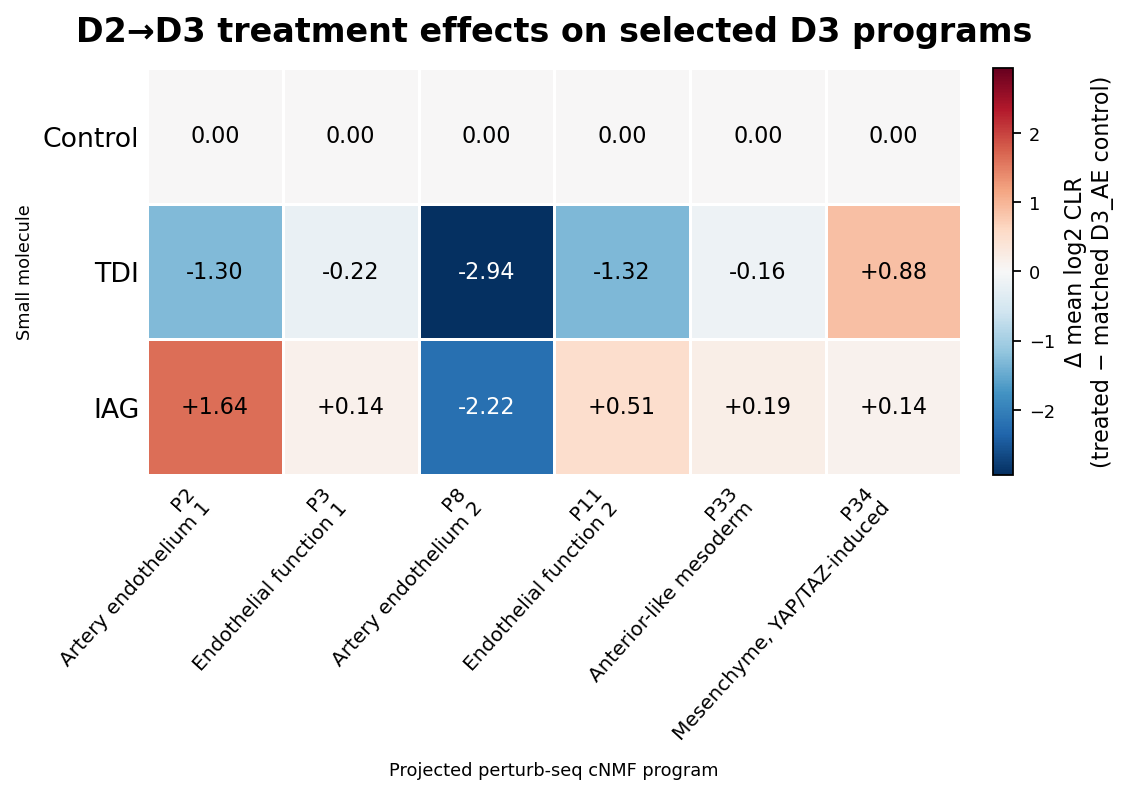

Saved figure and tables to: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/D2toD3_CLR_heatmap_P2_P3_P8_P11_P33_P34


In [6]:
vals = heatmap_values.to_numpy(dtype=float)
vmax = float(np.nanmax(np.abs(vals)))
if not np.isfinite(vmax) or vmax == 0:
    vmax = 1e-9

n_rows, n_cols = heatmap_values.shape
# Square data cells: aspect='equal'; figure dimensions leave room for long labels and colorbar.
fig, ax = plt.subplots(figsize=(10.2, 4.8))
mesh = ax.pcolormesh(
    np.arange(n_cols + 1),
    np.arange(n_rows + 1),
    vals,
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax,
    shading="flat",
    edgecolors="white",
    linewidth=1.2,
)
ax.set_aspect("equal")
ax.set_xlim(0, n_cols)
ax.set_ylim(n_rows, 0)
ax.set_xticks(np.arange(n_cols) + 0.5)
ax.set_yticks(np.arange(n_rows) + 0.5)
ax.set_xticklabels([PROGRAM_LABELS[p] for p in SELECTED_PROGRAMS], rotation=48, ha="right", fontsize=9)
ax.set_yticklabels(ROW_ORDER, fontsize=12)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title("D2→D3 treatment effects on selected D3 programs", fontsize=15, weight="bold", pad=12)
ax.set_xlabel("Projected perturb-seq cNMF program", labelpad=8)
ax.set_ylabel("Small molecule")

for i, treatment in enumerate(ROW_ORDER):
    for j, program in enumerate(SELECTED_PROGRAMS):
        value = heatmap_values.loc[treatment, program]
        if treatment == "Control":
            txt = "0.00"
        else:
            if STAR_BY == "padj_bh":
                stat_value = heatmap_qvalues.loc[treatment, program]
            elif STAR_BY == "pvalue":
                stat_value = heatmap_pvalues.loc[treatment, program]
            else:
                stat_value = np.nan
            txt = f"{value:+.2f}{significance_stars(stat_value)}"

        text_color = "white" if abs(value) > 0.62 * vmax else "black"
        ax.text(j + 0.5, i + 0.5, txt, ha="center", va="center", fontsize=10, color=text_color)

cbar = fig.colorbar(mesh, ax=ax, pad=0.025, fraction=0.045)
cbar.set_label("Δ mean log2 CLR\n(treated − matched D3_AE control)", fontsize=10)

fig.subplots_adjust(left=0.11, right=0.89, bottom=0.33, top=0.86)

stem = "D2toD3_TDI_IAG_CLR_heatmap_P2_P3_P8_P11_P33_P34_square_cells"
for ext in ["svg", "pdf", "png"]:
    fig.savefig(OUT_DIR / f"{stem}.{ext}", bbox_inches="tight", dpi=300 if ext == "png" else None)
plt.show()
plt.close(fig)

print("Saved figure and tables to:", OUT_DIR)

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
from IPython.display import display


# ============================================================
# SETTINGS
# ============================================================

H5AD_PATH = Path(
    "/scratch/users/edtng/20260325_Hippo_timecourse/"
    "perturbseq_cNMF_projection/"
    "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"
)

PROGRAM_META_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/"
    "data/program_activity_long_v4.csv"
)

OUT_DIR = Path(
    "/scratch/users/edtng/20260325_Hippo_timecourse/"
    "perturbseq_cNMF_matched_DE/program_score_DE_clr_all_programs"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

SCORE_KEY = "X_perturbseq_cNMF_usage"
SAMPLE_COL = "sample_name"

# Same CLR settings used for the previous selected-program analysis.
CLR_EPS = 1e-6
LOG_BASE = 2

CONTRASTS = [
    {
        "treatment": "TDI",
        "treated_condition": "D2_LM+TDI->D3_AE+TDI",
        "control_condition": "D3_AE",
    },
    {
        "treatment": "IAG",
        "treated_condition": "D2_LM+IAG->D3_AE+IAG",
        "control_condition": "D3_AE",
    },
]

# Condition-specific QC cutoffs.
MT_CUTOFFS = {
    "D3_AE": 3.25,
    "D2_LM+TDI->D3_AE+TDI": 7.0,
    "D2_LM+IAG->D3_AE+IAG": 3.75,
}

RIBO_CUTOFFS = {
    "D3_AE": 1.0,
    "D2_LM+TDI->D3_AE+TDI": 2.5,
    "D2_LM+IAG->D3_AE+IAG": 1.0,
}


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def parse_sample_name(sample_name):
    """
    Examples:
      D3_AE_rep1 -> condition=D3_AE, replicate=1
      D2_LM+TDI->D3_AE+TDI_rep2 -> condition=..., replicate=2
    """
    sample_name = str(sample_name)

    match = re.match(r"^(.*)_rep(\d+)$", sample_name)

    if match is None:
        raise ValueError(
            f"Could not parse condition and replicate from sample_name={sample_name!r}"
        )

    return match.group(1), int(match.group(2))


def program_number(program):
    match = re.fullmatch(r"P(\d+)", str(program))

    if match is None:
        raise ValueError(f"Invalid program name: {program!r}")

    return int(match.group(1))


def clr_transform_usage(usage, eps=1e-6, log_base=2):
    """
    Apply CLR to a cells x programs compositional usage matrix.

    Steps:
      1. Normalize each cell to sum to 1.
      2. Floor values at eps.
      3. Renormalize each cell.
      4. Take log2 or natural log.
      5. Subtract the mean log abundance across programs in each cell.
    """
    usage = np.asarray(usage, dtype=np.float64)

    row_sums = usage.sum(axis=1, keepdims=True)

    if np.any(row_sums <= 0):
        n_zero = int((row_sums.ravel() <= 0).sum())
        raise ValueError(
            f"{n_zero} cells have zero total program usage and cannot be CLR transformed."
        )

    usage = usage / row_sums
    usage = np.maximum(usage, eps)
    usage = usage / usage.sum(axis=1, keepdims=True)

    if log_base == 2:
        log_usage = np.log2(usage)
    elif log_base == "natural":
        log_usage = np.log(usage)
    else:
        raise ValueError("LOG_BASE must be 2 or 'natural'.")

    clr = log_usage - log_usage.mean(axis=1, keepdims=True)

    return clr.astype(np.float32)


def bh_adjust(pvalues):
    """
    Benjamini-Hochberg adjusted p-values.
    """
    pvalues = np.asarray(pvalues, dtype=float)
    adjusted = np.full(pvalues.shape, np.nan, dtype=float)

    valid = np.isfinite(pvalues)
    p = pvalues[valid]

    if len(p) == 0:
        return adjusted

    order = np.argsort(p)
    ranked = p[order]
    n = len(ranked)

    q_ranked = ranked * n / np.arange(1, n + 1)
    q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
    q_ranked = np.clip(q_ranked, 0, 1)

    q_original = np.empty_like(q_ranked)
    q_original[order] = q_ranked

    adjusted[valid] = q_original

    return adjusted


def load_program_labels(program_names):
    labels = {program: program for program in program_names}

    if not PROGRAM_META_PATH.exists():
        print("Program metadata not found:", PROGRAM_META_PATH)
        return labels

    meta = pd.read_csv(PROGRAM_META_PATH)

    if "program_name" not in meta.columns:
        print("program_name column not found in metadata.")
        return labels

    meta = meta.drop_duplicates("program_name")

    if "program_label" not in meta.columns:
        print("program_label column not found in metadata.")
        return labels

    for _, row in meta.iterrows():
        if pd.isna(row["program_name"]):
            continue

        program = f"P{int(float(row['program_name']))}"

        if program in labels and pd.notna(row["program_label"]):
            labels[program] = f"{program} - {row['program_label']}"

    return labels


# ============================================================
# LOAD PROJECTED DATA
# ============================================================

print("Loading:", H5AD_PATH)

adata = sc.read_h5ad(H5AD_PATH, backed="r")

print(adata)
print("obsm keys:", list(adata.obsm.keys()))

if SCORE_KEY not in adata.obsm:
    raise KeyError(
        f"{SCORE_KEY!r} not found in adata.obsm. "
        f"Available keys: {list(adata.obsm.keys())}"
    )

if SAMPLE_COL not in adata.obs.columns:
    raise KeyError(
        f"{SAMPLE_COL!r} not found in adata.obs. "
        f"Available columns: {list(adata.obs.columns)}"
    )

required_qc_columns = ["pct_counts_mt", "pct_counts_ribo"]

missing_qc_columns = [
    column
    for column in required_qc_columns
    if column not in adata.obs.columns
]

if missing_qc_columns:
    raise KeyError(
        f"Missing required QC columns: {missing_qc_columns}"
    )

usage = np.asarray(adata.obsm[SCORE_KEY])
obs = adata.obs.copy()

print("Usage matrix shape:", usage.shape)


# ============================================================
# GET ZERO-BASED PROGRAM NAMES P0-P49
# ============================================================

projection_meta = adata.uns.get(
    "perturbseq_cNMF_projection",
    {},
)

program_names = [
    str(value)
    for value in projection_meta.get("program_names", [])
]

if len(program_names) != usage.shape[1]:
    print(
        "Program names not found or length mismatch in uns; "
        "falling back to P0...P{K-1}."
    )
    program_names = [
        f"P{i}"
        for i in range(usage.shape[1])
    ]

program_order = np.argsort(
    [program_number(program) for program in program_names]
)

program_names = [
    program_names[index]
    for index in program_order
]

usage = usage[:, program_order]

expected_programs = [
    f"P{i}"
    for i in range(50)
]

if program_names != expected_programs:
    raise ValueError(
        "Expected zero-based P0-P49 programs.\n"
        f"Observed first programs: {program_names[:10]}\n"
        f"Observed last programs: {program_names[-10:]}"
    )

print("Confirmed programs:", program_names[:5], "...", program_names[-5:])


# ============================================================
# PARSE CONDITION AND REPLICATE
# ============================================================

parsed_samples = obs[SAMPLE_COL].astype(str).map(
    parse_sample_name
)

obs["condition"] = [
    parsed[0]
    for parsed in parsed_samples
]

obs["replicate"] = [
    parsed[1]
    for parsed in parsed_samples
]

obs["pct_counts_mt"] = pd.to_numeric(
    obs["pct_counts_mt"],
    errors="coerce",
)

obs["pct_counts_ribo"] = pd.to_numeric(
    obs["pct_counts_ribo"],
    errors="coerce",
)


# ============================================================
# RESTRICT TO RELEVANT CONDITIONS AND APPLY QC FILTERS
# ============================================================

relevant_conditions = sorted(
    {
        contrast["treated_condition"]
        for contrast in CONTRASTS
    }
    |
    {
        contrast["control_condition"]
        for contrast in CONTRASTS
    }
)

print("Relevant conditions:")
for condition in relevant_conditions:
    print(" ", condition)

missing_cutoffs = [
    condition
    for condition in relevant_conditions
    if condition not in MT_CUTOFFS
    or condition not in RIBO_CUTOFFS
]

if missing_cutoffs:
    raise ValueError(
        f"Missing QC cutoffs for: {missing_cutoffs}"
    )

relevant_mask = (
    obs["condition"]
    .isin(relevant_conditions)
    .to_numpy()
)

keep_mask = relevant_mask.copy()

filter_records = []

for condition in relevant_conditions:
    condition_mask = (
        obs["condition"].to_numpy()
        == condition
    )

    fail_mt = (
        condition_mask
        &
        (
            obs["pct_counts_mt"].to_numpy()
            >= MT_CUTOFFS[condition]
        )
    )

    fail_ribo = (
        condition_mask
        &
        (
            obs["pct_counts_ribo"].to_numpy()
            <= RIBO_CUTOFFS[condition]
        )
    )

    fail_any = fail_mt | fail_ribo

    keep_mask &= ~fail_any

    n_before = int(condition_mask.sum())
    n_removed = int(fail_any.sum())

    filter_records.append(
        {
            "condition": condition,
            "pct_counts_mt_cutoff": MT_CUTOFFS[condition],
            "pct_counts_ribo_cutoff": RIBO_CUTOFFS[condition],
            "n_before": n_before,
            "n_fail_mt": int(fail_mt.sum()),
            "n_fail_low_ribo": int(fail_ribo.sum()),
            "n_removed": n_removed,
            "n_after": n_before - n_removed,
            "fraction_removed": (
                n_removed / n_before
                if n_before > 0
                else np.nan
            ),
        }
    )

filter_summary = pd.DataFrame(filter_records)

print("\nQC filter summary:")
display(filter_summary)

obs_filtered = obs.loc[keep_mask].copy()
usage_filtered = usage[keep_mask, :]

print(
    "\nCells before QC filtering:",
    f"{int(relevant_mask.sum()):,}",
)

print(
    "Cells after QC filtering:",
    f"{obs_filtered.shape[0]:,}",
)


# ============================================================
# CELL-LEVEL CLR ACROSS ALL 50 PROGRAMS
# ============================================================

clr_usage = clr_transform_usage(
    usage_filtered,
    eps=CLR_EPS,
    log_base=LOG_BASE,
)

print("CLR shape:", clr_usage.shape)

clr_row_means = clr_usage.mean(axis=1)

print(
    "CLR row mean range:",
    float(clr_row_means.min()),
    float(clr_row_means.max()),
)

if not np.allclose(
    clr_row_means,
    0,
    atol=1e-5,
):
    print(
        "WARNING: CLR row means are not all close to zero."
    )


# ============================================================
# AGGREGATE CLR VALUES PER BIOLOGICAL SAMPLE
# ============================================================

clr_df = pd.DataFrame(
    clr_usage,
    index=obs_filtered.index.astype(str),
    columns=program_names,
)

clr_df[SAMPLE_COL] = (
    obs_filtered[SAMPLE_COL]
    .astype(str)
    .to_numpy()
)

sample_clr_mean = (
    clr_df
    .groupby(
        SAMPLE_COL,
        observed=True,
    )[program_names]
    .mean()
)

sample_metadata = (
    obs_filtered[
        [
            SAMPLE_COL,
            "condition",
            "replicate",
        ]
    ]
    .drop_duplicates(SAMPLE_COL)
    .set_index(SAMPLE_COL)
    .loc[sample_clr_mean.index]
)

print(
    "Sample-level CLR matrix shape:",
    sample_clr_mean.shape,
)

display(sample_metadata)


# ============================================================
# PAIRED STATISTICS FOR ALL P0-P49
# ============================================================

program_labels = load_program_labels(
    program_names
)

result_records = []
paired_records = []

for contrast in CONTRASTS:
    treatment = contrast["treatment"]
    treated_condition = contrast["treated_condition"]
    control_condition = contrast["control_condition"]

    treated_meta = sample_metadata[
        sample_metadata["condition"]
        == treated_condition
    ].copy()

    control_meta = sample_metadata[
        sample_metadata["condition"]
        == control_condition
    ].copy()

    treated_by_replicate = {
        int(row["replicate"]): sample_name
        for sample_name, row in treated_meta.iterrows()
    }

    control_by_replicate = {
        int(row["replicate"]): sample_name
        for sample_name, row in control_meta.iterrows()
    }

    matched_replicates = sorted(
        set(treated_by_replicate)
        &
        set(control_by_replicate)
    )

    print(
        "\n",
        treatment,
        ":",
        treated_condition,
        "vs",
        control_condition,
        "| matched replicates:",
        matched_replicates,
    )

    if len(matched_replicates) < 2:
        raise ValueError(
            f"Not enough matched replicates for "
            f"{treated_condition} vs {control_condition}"
        )

    for program in program_names:
        control_values = []
        treated_values = []
        paired_differences = []

        for replicate in matched_replicates:
            control_sample = (
                control_by_replicate[replicate]
            )

            treated_sample = (
                treated_by_replicate[replicate]
            )

            control_value = float(
                sample_clr_mean.loc[
                    control_sample,
                    program,
                ]
            )

            treated_value = float(
                sample_clr_mean.loc[
                    treated_sample,
                    program,
                ]
            )

            paired_difference = (
                treated_value
                - control_value
            )

            control_values.append(
                control_value
            )

            treated_values.append(
                treated_value
            )

            paired_differences.append(
                paired_difference
            )

            paired_records.append(
                {
                    "treatment": treatment,
                    "treated_condition": treated_condition,
                    "control_condition": control_condition,
                    "program": program,
                    "program_label": program_labels[program],
                    "replicate": replicate,
                    "control_sample": control_sample,
                    "treated_sample": treated_sample,
                    "control_clr": control_value,
                    "treated_clr": treated_value,
                    "paired_diff_clr": paired_difference,
                }
            )

        control_values = np.asarray(
            control_values,
            dtype=float,
        )

        treated_values = np.asarray(
            treated_values,
            dtype=float,
        )

        paired_differences = np.asarray(
            paired_differences,
            dtype=float,
        )

        difference_sd = np.std(
            paired_differences,
            ddof=1,
        )

        if (
            len(paired_differences) >= 2
            and np.isfinite(difference_sd)
            and difference_sd > 0
        ):
            t_statistic, pvalue = stats.ttest_rel(
                treated_values,
                control_values,
                nan_policy="omit",
            )
        else:
            t_statistic = np.nan
            pvalue = np.nan

        result_records.append(
            {
                "treatment": treatment,
                "treated_condition": treated_condition,
                "control_condition": control_condition,
                "program": program,
                "program_label": program_labels[program],
                "n_matched_pairs": len(matched_replicates),
                "mean_control_clr": float(
                    np.mean(control_values)
                ),
                "mean_treated_clr": float(
                    np.mean(treated_values)
                ),
                "mean_diff_clr": float(
                    np.mean(paired_differences)
                ),
                "sd_diff_clr": float(
                    difference_sd
                ),
                "t_statistic": (
                    float(t_statistic)
                    if np.isfinite(t_statistic)
                    else np.nan
                ),
                "pvalue": (
                    float(pvalue)
                    if np.isfinite(pvalue)
                    else np.nan
                ),
                "n_positive_diffs": int(
                    (paired_differences > 0).sum()
                ),
                "n_negative_diffs": int(
                    (paired_differences < 0).sum()
                ),
            }
        )


# ============================================================
# BUILD RESULTS TABLE AND MULTIPLE-TESTING CORRECTION
# ============================================================

all_program_results = pd.DataFrame(
    result_records
)

paired_values = pd.DataFrame(
    paired_records
)

# BH correction separately within TDI and IAG,
# each across all 50 programs.
all_program_results["padj_bh"] = np.nan

for treatment, indices in (
    all_program_results
    .groupby("treatment")
    .groups
    .items()
):
    all_program_results.loc[
        indices,
        "padj_bh",
    ] = bh_adjust(
        all_program_results.loc[
            indices,
            "pvalue",
        ].to_numpy()
    )

# Additional global BH correction across all 100 tests.
all_program_results["padj_bh_global"] = (
    bh_adjust(
        all_program_results[
            "pvalue"
        ].to_numpy()
    )
)

# Sort TDI first, IAG second, and P0-P49.
treatment_dtype = pd.CategoricalDtype(
    categories=["TDI", "IAG"],
    ordered=True,
)

all_program_results["treatment"] = (
    all_program_results["treatment"]
    .astype(treatment_dtype)
)

all_program_results[
    "program_number"
] = (
    all_program_results["program"]
    .map(program_number)
)

all_program_results = (
    all_program_results
    .sort_values(
        [
            "treatment",
            "program_number",
        ]
    )
    .drop(
        columns="program_number"
    )
    .reset_index(
        drop=True
    )
)

print(
    "\nFinal results shape:",
    all_program_results.shape,
)


# ============================================================
# SAVE OUTPUTS
# ============================================================

RESULTS_TSV = (
    OUT_DIR
    / "D2toD3_TDI_IAG_CLR_paired_statistics_all_50_programs.tsv"
)

RESULTS_CSV = (
    OUT_DIR
    / "D2toD3_TDI_IAG_CLR_paired_statistics_all_50_programs.csv"
)

RESULTS_HTML = (
    OUT_DIR
    / "D2toD3_TDI_IAG_CLR_paired_statistics_all_50_programs.html"
)

PAIRED_TSV = (
    OUT_DIR
    / "D2toD3_TDI_IAG_CLR_paired_replicate_values_all_50_programs.tsv"
)

SAMPLE_CLR_TSV = (
    OUT_DIR
    / "D2toD3_sample_mean_CLR_all_50_programs.tsv"
)

SAMPLE_META_TSV = (
    OUT_DIR
    / "D2toD3_sample_mean_CLR_metadata.tsv"
)

QC_SUMMARY_TSV = (
    OUT_DIR
    / "D2toD3_CLR_analysis_qc_filter_summary.tsv"
)

all_program_results.to_csv(
    RESULTS_TSV,
    sep="\t",
    index=False,
)

all_program_results.to_csv(
    RESULTS_CSV,
    index=False,
)

all_program_results.to_html(
    RESULTS_HTML,
    index=False,
    float_format=lambda value: f"{value:.6g}",
)

paired_values.to_csv(
    PAIRED_TSV,
    sep="\t",
    index=False,
)

sample_clr_mean.to_csv(
    SAMPLE_CLR_TSV,
    sep="\t",
)

sample_metadata.to_csv(
    SAMPLE_META_TSV,
    sep="\t",
)

filter_summary.to_csv(
    QC_SUMMARY_TSV,
    sep="\t",
    index=False,
)


# ============================================================
# DISPLAY FORMATTED TABLE
# ============================================================

display_columns = [
    "treatment",
    "treated_condition",
    "control_condition",
    "program",
    "program_label",
    "n_matched_pairs",
    "mean_control_clr",
    "mean_treated_clr",
    "mean_diff_clr",
    "sd_diff_clr",
    "t_statistic",
    "pvalue",
    "n_positive_diffs",
    "n_negative_diffs",
    "padj_bh",
    "padj_bh_global",
]

max_abs_effect = float(
    all_program_results[
        "mean_diff_clr"
    ]
    .abs()
    .max()
)

styled_table = (
    all_program_results[
        display_columns
    ]
    .style
    .format(
        {
            "mean_control_clr": "{:.6f}",
            "mean_treated_clr": "{:.6f}",
            "mean_diff_clr": "{:.6f}",
            "sd_diff_clr": "{:.6f}",
            "t_statistic": "{:.6f}",
            "pvalue": "{:.6g}",
            "padj_bh": "{:.6g}",
            "padj_bh_global": "{:.6g}",
        }
    )
    .background_gradient(
        subset=["mean_diff_clr"],
        cmap="RdBu_r",
        vmin=-max_abs_effect,
        vmax=max_abs_effect,
    )
)

display(styled_table)


# ============================================================
# PRINT OUTPUT PATHS AND TOP RESULTS
# ============================================================

print("\nSaved outputs:")
print(" ", RESULTS_TSV)
print(" ", RESULTS_CSV)
print(" ", RESULTS_HTML)
print(" ", PAIRED_TSV)
print(" ", SAMPLE_CLR_TSV)
print(" ", SAMPLE_META_TSV)
print(" ", QC_SUMMARY_TSV)

print("\nTop TDI programs by nominal p-value:")
display(
    all_program_results[
        all_program_results["treatment"] == "TDI"
    ]
    .sort_values("pvalue")
    .head(10)[
        display_columns
    ]
)

print("\nTop IAG programs by nominal p-value:")
display(
    all_program_results[
        all_program_results["treatment"] == "IAG"
    ]
    .sort_values("pvalue")
    .head(10)[
        display_columns
    ]
)

print("\nSignificant after within-treatment BH correction:")
display(
    all_program_results[
        all_program_results["padj_bh"] < 0.05
    ][
        display_columns
    ]
)

adata.file.close()

Loading: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad
AnnData object with n_obs × n_vars = 212891 × 62757 backed at '/scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad'
    obs: 'guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 'biological_sample', 'plate', 'sublibID', 'sample_name', 'perturbseq_cNMF_P0_usage', 'perturbseq_cNMF_P1_usage', 'perturbseq_cNMF_P2_usage', 'perturbseq_cNMF_P3_usage', 'perturbseq_cNMF_P4_usage', 'perturbseq_cNMF_P5_usage', 'perturbseq_cNMF_P6_usage', 'perturbseq_cNMF_P7_usage', 'perturbseq_cNMF_P8_usage', 'perturbseq_cNMF_P9_usage', 'perturbseq_cNMF_P10_usage', 'perturbseq_cNMF_P11_usage', 'perturbseq_cNMF_P12_usage', 'perturbseq_cNMF_P13

,condition,pct_counts_mt_cutoff,pct_counts_ribo_cutoff,n_before,n_fail_mt,n_fail_low_ribo,n_removed,n_after,fraction_removed
0,D2_LM+IAG->D3_AE+IAG,3.75,1.0,5307,2622,2721,2820,2487,0.531374
1,D2_LM+TDI->D3_AE+TDI,7.00,2.5,15140,1373,5530,5587,9553,0.369022
2,D3_AE,3.25,1.0,8704,5776,4148,6017,2687,0.691291



Cells before QC filtering: 29,151
Cells after QC filtering: 14,727
CLR shape: (14727, 50)
CLR row mean range: -3.2424927098873013e-07 3.4332276754867053e-07
Sample-level CLR matrix shape: (9, 50)


,condition,replicate
sample_name,,
D2_LM+IAG->D3_AE+IAG_rep1,D2_LM+IAG->D3_AE+IAG,1
D2_LM+IAG->D3_AE+IAG_rep2,D2_LM+IAG->D3_AE+IAG,2
D2_LM+IAG->D3_AE+IAG_rep3,D2_LM+IAG->D3_AE+IAG,3
D2_LM+TDI->D3_AE+TDI_rep1,D2_LM+TDI->D3_AE+TDI,1
D2_LM+TDI->D3_AE+TDI_rep2,D2_LM+TDI->D3_AE+TDI,2
D2_LM+TDI->D3_AE+TDI_rep3,D2_LM+TDI->D3_AE+TDI,3
D3_AE_rep1,D3_AE,1
D3_AE_rep2,D3_AE,2
D3_AE_rep3,D3_AE,3



 TDI : D2_LM+TDI->D3_AE+TDI vs D3_AE | matched replicates: [1, 2, 3]

 IAG : D2_LM+IAG->D3_AE+IAG vs D3_AE | matched replicates: [1, 2, 3]

Final results shape: (100, 16)


...

,treatment,treated_condition,control_condition,program,program_label,n_matched_pairs,mean_control_clr,mean_treated_clr,mean_diff_clr,sd_diff_clr,t_statistic,pvalue,n_positive_diffs,n_negative_diffs,padj_bh,padj_bh_global
11,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P11,P11 - P11 — EC angiogenic,3,-0.399080,-1.722189,-1.323109,0.320136,-7.158491,0.018961,0,3,0.742974,0.677423
7,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P7,P7 - P7 — pluripotency,3,-1.468753,3.328639,4.797392,1.993255,4.168723,0.053009,3,0,0.742974,0.677423
34,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P34,P34 - P34 — contractile/YAP,3,-1.585380,-0.700550,0.884830,0.391611,3.913498,0.059523,3,0,0.742974,0.677423
15,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P15,P15 - P15 — endothelial,3,1.655501,-1.656134,-3.311635,1.844720,-3.109372,0.089729,0,3,0.742974,0.677423
27,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P27,P27 - P27 — mesenchymal ECM,3,-1.632947,-0.110842,1.522105,0.915051,2.881111,0.102314,3,0,0.742974,0.677423
24,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P24,P24 - P24 — HOX patterning,3,-1.536123,7.934261,9.470384,6.533123,2.510773,0.128707,3,0,0.742974,0.677423
17,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P17,P17 - P17 — epithelial-like,3,-1.632947,1.222015,2.854962,2.032419,2.433031,0.135440,3,0,0.742974,0.677423
2,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P2,P2 - P2 — EC migratory,3,-0.476531,-1.778702,-1.302171,1.248254,-1.806866,0.212526,1,2,0.742974,0.677423
14,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P14,P14 - P14 — lateral mesoderm,3,-0.709804,4.001894,4.711698,5.093355,1.602264,0.250267,2,1,0.742974,0.677423
36,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P36,P36 - P36 — p53 stress,3,-1.129709,-1.531150,-0.401441,0.483849,-1.437052,0.287252,1,2,0.742974,0.677423



Top IAG programs by nominal p-value:


,treatment,treated_condition,control_condition,program,program_label,n_matched_pairs,mean_control_clr,mean_treated_clr,mean_diff_clr,sd_diff_clr,t_statistic,pvalue,n_positive_diffs,n_negative_diffs,padj_bh,padj_bh_global
52,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P2,P2 - P2 — EC migratory,3,-0.476531,1.167483,1.644013,1.114747,2.554405,0.125131,3,0,0.471936,0.677423
70,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P20,P20 - P20 — transitional mesoderm,3,11.415167,6.549355,-4.865812,3.381348,-2.492448,0.130251,0,3,0.471936,0.677423
62,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P12,P12 - P12 — G2/M,3,11.844480,14.581159,2.736679,3.155922,1.501959,0.271946,2,1,0.471936,0.677423
85,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P35,P35 - P35 — EMT/ECM,3,16.836787,17.360530,0.523744,0.616883,1.470538,0.279224,3,0,0.471936,0.677423
64,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P14,P14 - P14 — lateral mesoderm,3,-0.709804,0.273085,0.982888,1.159319,1.468458,0.279715,2,1,0.471936,0.677423
55,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P5,P5 - P5 — translation,3,-1.511430,-1.447726,0.063704,0.078352,1.408230,0.294394,3,0,0.471936,0.677423
82,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P32,P32 - P32 — chromatin-histone,3,3.554321,1.390189,-2.164132,2.831304,-1.323908,0.316586,1,2,0.471936,0.677423
61,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P11,P11 - P11 — EC angiogenic,3,-0.399080,0.107372,0.506452,0.754627,1.162430,0.365015,3,0,0.471936,0.677423
84,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P34,P34 - P34 — contractile/YAP,3,-1.585380,-1.447726,0.137654,0.206416,1.155065,0.367425,3,0,0.471936,0.677423
75,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P25,P25 - P25 — RNA-processing,3,-1.622292,-1.447726,0.174566,0.270346,1.118408,0.379699,3,0,0.471936,0.677423



Significant after within-treatment BH correction:


,treatment,treated_condition,control_condition,program,program_label,n_matched_pairs,mean_control_clr,mean_treated_clr,mean_diff_clr,sd_diff_clr,t_statistic,pvalue,n_positive_diffs,n_negative_diffs,padj_bh,padj_bh_global


# Build Hunter-facing cell × cNMF-program AnnData

`adata_out.X` is the cell-level CLR program vector minus the mean CLR vector
of the replicate-matched control sample. Subtraction is appropriate because
CLR values are already on a log-ratio scale; dividing CLR values is not.

In [2]:
# %% [markdown]
# # Build Hunter-facing cell × cNMF-program AnnData
#
# `adata_out.X` is the cell-level CLR program vector minus the mean CLR vector
# of the replicate-matched control sample. Subtraction is appropriate because
# CLR values are already on a log-ratio scale; dividing CLR values is not.

# %%
from pathlib import Path
import re

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc


# ============================================================
# SETTINGS
# ============================================================

SOURCE_H5AD = Path(
    "/scratch/users/edtng/20260325_Hippo_timecourse/"
    "perturbseq_cNMF_projection/"
    "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"
)

PROGRAM_META_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/"
    "data/program_activity_long_v4.csv"
)

OUT_DIR = SOURCE_H5AD.parent / "hunter_cell_x_cnmf_clr"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_ALL_CELLS = OUT_DIR / "Hippo_timecourse_cells_x_cNMF_CLR_delta_matched_control.all_cells.h5ad"
OUT_QC_FILTERED = OUT_DIR / "Hippo_timecourse_cells_x_cNMF_CLR_delta_matched_control.qc_filtered.h5ad"

SCORE_KEY = "X_perturbseq_cNMF_usage"
RAW_SCORE_KEY = "X_perturbseq_cNMF_usage_raw"
SAMPLE_COL = "sample_name"

CLR_EPS = 1e-6
LOG_BASE = 2
WRITE_ALL_CELLS = True
WRITE_QC_FILTERED = True

# Each condition is compared to the control at the same collected stage.
CONTROL_CONDITION_MAP = {
    "D0_hPSC": "D0_hPSC",
    "D1_MPS": "D1_MPS",
    "D1_MPS+TDI": "D1_MPS",
    "D1_MPS+IAG": "D1_MPS",
    "D1.33_LM": "D1.33_LM",
    "D1.33_LM+TDI": "D1.33_LM",
    "D1.33_LM+IAG": "D1.33_LM",
    "D1.67_LM": "D1.67_LM",
    "D1.67_LM+TDI": "D1.67_LM",
    "D1.67_LM+IAG": "D1.67_LM",
    "D2_LM": "D2_LM",
    "D2_LM+TDI": "D2_LM",
    "D2_LM+IAG": "D2_LM",
    "D3_AE": "D3_AE",
    "D3_AE+TDI": "D3_AE",
    "D3_AE+IAG": "D3_AE",
    # These were collected at the D3 endpoint, so the matched control is D3_AE.
    "D2_LM+TDI->D3_AE+TDI": "D3_AE",
    "D2_LM+IAG->D3_AE+IAG": "D3_AE",
}

# The same condition-specific QC thresholds used in the prior analyses.
RIBO_CUTOFFS = {
    "D0_hPSC": 2.4,
    "D1_MPS": 2.3,
    "D1_MPS+TDI": 2.5,
    "D1_MPS+IAG": 2.2,
    "D1.33_LM": 1.9,
    "D1.33_LM+TDI": 2.1,
    "D1.33_LM+IAG": 2.2,
    "D1.67_LM": 2.0,
    "D1.67_LM+TDI": 2.2,
    "D1.67_LM+IAG": 1.9,
    "D2_LM": 2.0,
    "D2_LM+TDI": 2.4,
    "D2_LM+IAG": 1.9,
    "D3_AE": 1.0,
    "D3_AE+TDI": 2.0,
    "D3_AE+IAG": 1.0,
    "D2_LM+TDI->D3_AE+TDI": 2.5,
    "D2_LM+IAG->D3_AE+IAG": 1.0,
}

MT_CUTOFFS = {
    "D0_hPSC": 5.5,
    "D1_MPS": 3.0,
    "D1_MPS+TDI": 3.0,
    "D1_MPS+IAG": 4.0,
    "D1.33_LM": 3.5,
    "D1.33_LM+TDI": 3.75,
    "D1.33_LM+IAG": 5.0,
    "D1.67_LM": 4.0,
    "D1.67_LM+TDI": 5.5,
    "D1.67_LM+IAG": 3.5,
    "D2_LM": 6.5,
    "D2_LM+TDI": 8.0,
    "D2_LM+IAG": 3.5,
    "D3_AE": 3.25,
    "D3_AE+TDI": 7.0,
    "D3_AE+IAG": 3.75,
    "D2_LM+TDI->D3_AE+TDI": 7.0,
    "D2_LM+IAG->D3_AE+IAG": 3.75,
}


# ============================================================
# HELPERS
# ============================================================

def parse_sample_name(sample_name: str):
    """Parse names such as D2_LM+TDI_rep2."""
    match = re.match(r"^(.*)_rep(\d+)$", str(sample_name))
    if match is None:
        raise ValueError(f"Could not parse condition/replicate from {sample_name!r}")
    return match.group(1), int(match.group(2))


def program_number(program: str) -> int:
    match = re.fullmatch(r"P(\d+)", str(program))
    if match is None:
        raise ValueError(f"Invalid program name {program!r}")
    return int(match.group(1))


def normalize_usage(usage: np.ndarray) -> np.ndarray:
    usage = np.asarray(usage, dtype=np.float64)
    row_sums = usage.sum(axis=1, keepdims=True)
    if np.any(row_sums <= 0):
        raise ValueError(f"{int((row_sums.ravel() <= 0).sum())} cells have zero total usage")
    return usage / row_sums


def clr_transform(usage: np.ndarray, eps: float = 1e-6, log_base=2) -> np.ndarray:
    usage = normalize_usage(usage)
    usage = np.maximum(usage, eps)
    usage = usage / usage.sum(axis=1, keepdims=True)
    if log_base == 2:
        log_usage = np.log2(usage)
    elif log_base == "natural":
        log_usage = np.log(usage)
    else:
        raise ValueError("LOG_BASE must be 2 or 'natural'")
    clr = log_usage - log_usage.mean(axis=1, keepdims=True)
    return clr.astype(np.float32)


def load_program_var(program_names):
    var = pd.DataFrame(index=pd.Index(program_names, name="program"))
    var["program_name"] = program_names
    var["program_id_zero_based"] = [program_number(p) for p in program_names]
    var["program_label"] = program_names

    if PROGRAM_META_PATH.exists():
        meta = pd.read_csv(PROGRAM_META_PATH).drop_duplicates("program_name")
        if "program_label" in meta.columns:
            label_map = {
                f"P{int(float(row.program_name))}": str(row.program_label)
                for row in meta.itertuples()
                if pd.notna(row.program_name) and pd.notna(row.program_label)
            }
            var["program_label"] = [label_map.get(p, p) for p in program_names]
    return var


# ============================================================
# LOAD SOURCE PROJECTION
# ============================================================

print("Loading source projection:", SOURCE_H5AD)
source = sc.read_h5ad(SOURCE_H5AD, backed="r")

if SCORE_KEY not in source.obsm:
    raise KeyError(f"{SCORE_KEY!r} not found in source.obsm")
if SAMPLE_COL not in source.obs.columns:
    raise KeyError(f"{SAMPLE_COL!r} not found in source.obs")

usage = np.asarray(source.obsm[SCORE_KEY])
obs = source.obs.copy()

projection_meta = source.uns.get("perturbseq_cNMF_projection", {})
program_names = [str(x) for x in projection_meta.get("program_names", [])]
if len(program_names) != usage.shape[1]:
    program_names = [f"P{i}" for i in range(usage.shape[1])]

program_order = np.argsort([program_number(p) for p in program_names])
program_names = [program_names[i] for i in program_order]
usage = usage[:, program_order]

expected = [f"P{i}" for i in range(usage.shape[1])]
if program_names != expected:
    raise ValueError(f"Expected contiguous zero-based programs; observed {program_names[:5]} ... {program_names[-5:]}")

usage_norm = normalize_usage(usage).astype(np.float32)
clr = clr_transform(usage_norm, eps=CLR_EPS, log_base=LOG_BASE)

print("Cells:", source.n_obs)
print("Programs:", len(program_names))
print("CLR row-mean max abs:", float(np.max(np.abs(clr.mean(axis=1)))))


# ============================================================
# PARSE SAMPLE METADATA AND QC FLAGS
# ============================================================

parsed = obs[SAMPLE_COL].astype(str).map(parse_sample_name)
obs["condition"] = [x[0] for x in parsed]
obs["replicate"] = [x[1] for x in parsed]
obs["treatment"] = np.select(
    [obs["condition"].str.contains("TDI"), obs["condition"].str.contains("IAG")],
    ["TDI", "IAG"],
    default="control",
)

unknown_conditions = sorted(set(obs["condition"]) - set(CONTROL_CONDITION_MAP))
if unknown_conditions:
    raise ValueError(f"Missing control mapping for conditions: {unknown_conditions}")

obs["matching_control_condition"] = obs["condition"].map(CONTROL_CONDITION_MAP)
obs["matching_control_sample"] = [
    f"{control_condition}_rep{replicate}"
    for control_condition, replicate in zip(obs["matching_control_condition"], obs["replicate"])
]
obs["is_control_condition"] = obs["condition"] == obs["matching_control_condition"]

for col in ["pct_counts_mt", "pct_counts_ribo"]:
    if col not in obs.columns:
        raise KeyError(f"Required QC column {col!r} is absent")
    obs[col] = pd.to_numeric(obs[col], errors="coerce")

qc_pass = np.ones(len(obs), dtype=bool)
for condition in sorted(obs["condition"].unique()):
    if condition not in MT_CUTOFFS or condition not in RIBO_CUTOFFS:
        raise ValueError(f"Missing QC cutoff for {condition}")
    cond = obs["condition"].to_numpy() == condition
    fail = cond & (
        (obs["pct_counts_mt"].to_numpy() >= MT_CUTOFFS[condition])
        | (obs["pct_counts_ribo"].to_numpy() <= RIBO_CUTOFFS[condition])
    )
    qc_pass &= ~fail

obs["qc_pass_condition_specific"] = qc_pass
print("QC-pass cells:", int(qc_pass.sum()), "/", len(qc_pass))


# ============================================================
# CONTROL BASELINES
# ============================================================

sample_values = obs[SAMPLE_COL].astype(str).to_numpy()
condition_values = obs["condition"].astype(str).to_numpy()

# Replicate-matched control sample means, calculated from QC-pass control cells.
control_samples_needed = sorted(obs["matching_control_sample"].unique())
control_sample_means = {}

for control_sample in control_samples_needed:
    mask = qc_pass & (sample_values == control_sample)
    if mask.sum() == 0:
        raise ValueError(
            f"No QC-passing cells found for matched control sample {control_sample!r}. "
            "Check sample names or QC thresholds."
        )
    control_sample_means[control_sample] = clr[mask].mean(axis=0).astype(np.float32)

# Pooled matching-control-condition means, also from QC-pass control cells.
control_conditions_needed = sorted(obs["matching_control_condition"].unique())
control_condition_means = {}
for control_condition in control_conditions_needed:
    mask = qc_pass & (condition_values == control_condition)
    if mask.sum() == 0:
        raise ValueError(f"No QC-passing cells found for control condition {control_condition!r}")
    control_condition_means[control_condition] = clr[mask].mean(axis=0).astype(np.float32)

# Subtract replicate-matched control mean from every cell.
delta_matched_rep = np.empty_like(clr, dtype=np.float32)
delta_control_condition = np.empty_like(clr, dtype=np.float32)

for sample_name in obs[SAMPLE_COL].astype(str).unique():
    mask = sample_values == sample_name
    first_index = np.flatnonzero(mask)[0]
    control_sample = str(obs.iloc[first_index]["matching_control_sample"])
    control_condition = str(obs.iloc[first_index]["matching_control_condition"])
    delta_matched_rep[mask] = clr[mask] - control_sample_means[control_sample]
    delta_control_condition[mask] = clr[mask] - control_condition_means[control_condition]

# Validation: every control replicate's QC-pass sample mean should be ~0 in X.
validation = []
for control_sample in control_samples_needed:
    mask = qc_pass & (sample_values == control_sample)
    mean_abs_max = float(np.max(np.abs(delta_matched_rep[mask].mean(axis=0))))
    validation.append({
        "control_sample": control_sample,
        "n_qc_cells": int(mask.sum()),
        "max_abs_mean_delta": mean_abs_max,
    })
validation_df = pd.DataFrame(validation)
print("Control-centering validation:")
print(validation_df.to_string(index=False))


# ============================================================
# CREATE CELL × PROGRAM ANNDATA
# ============================================================

var = load_program_var(program_names)

hunter = ad.AnnData(
    X=delta_matched_rep,
    obs=obs.copy(),
    var=var,
    dtype=np.float32,
)

# Useful alternative representations with the same cells × programs shape.
hunter.layers["projected_usage_normalized"] = usage_norm
hunter.layers["clr"] = clr
hunter.layers["clr_delta_vs_control_condition_mean"] = delta_control_condition

if RAW_SCORE_KEY in source.obsm:
    raw_usage = np.asarray(source.obsm[RAW_SCORE_KEY])[:, program_order].astype(np.float32)
    hunter.layers["projected_usage_raw"] = raw_usage

# Preserve UMAP if present and aligned to the same cells.
if "X_umap" in source.obsm:
    hunter.obsm["X_umap"] = np.asarray(source.obsm["X_umap"]).astype(np.float32)

hunter.uns["description"] = (
    "Cell x zero-based projected cNMF program AnnData. X contains cell-level CLR "
    "minus the mean CLR vector of the replicate-matched control sample."
)
hunter.uns["X_representation"] = "clr_delta_vs_matched_control_replicate_mean"
hunter.uns["clr_parameters"] = {
    "epsilon": float(CLR_EPS),
    "log_base": str(LOG_BASE),
    "performed_across": "all programs within each cell",
}
hunter.uns["control_mapping"] = CONTROL_CONDITION_MAP
hunter.uns["control_baseline_cells"] = "QC-pass control cells only"
hunter.uns["control_centering_validation"] = validation_df
hunter.uns["source_h5ad"] = str(SOURCE_H5AD)

# Save small metadata tables alongside the h5ad.
control_map_df = (
    obs[[SAMPLE_COL, "condition", "replicate", "matching_control_condition", "matching_control_sample", "treatment"]]
    .drop_duplicates(SAMPLE_COL)
    .sort_values(["condition", "replicate"])
)
control_map_df.to_csv(OUT_DIR / "sample_to_matched_control_mapping.tsv", sep="\t", index=False)
var.to_csv(OUT_DIR / "program_metadata.tsv", sep="\t")
validation_df.to_csv(OUT_DIR / "control_centering_validation.tsv", sep="\t", index=False)

if WRITE_ALL_CELLS:
    print("Writing all-cell file:", OUT_ALL_CELLS)
    hunter.write_h5ad(OUT_ALL_CELLS, compression="gzip")

if WRITE_QC_FILTERED:
    print("Writing QC-filtered file:", OUT_QC_FILTERED)
    hunter_qc = hunter[hunter.obs["qc_pass_condition_specific"].to_numpy()].copy()
    hunter_qc.write_h5ad(OUT_QC_FILTERED, compression="gzip")
    print(hunter_qc)

print("\nHunter-facing AnnData:")
print(hunter)
print("\nX meaning:", hunter.uns["X_representation"])
print("Layers:", list(hunter.layers.keys()))
print("Output directory:", OUT_DIR)

source.file.close()


Loading source projection: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad
Cells: 212891
Programs: 50
CLR row-mean max abs: 9.155273232863692e-07
QC-pass cells: 99416 / 212891
Control-centering validation:
control_sample  n_qc_cells  max_abs_mean_delta
  D0_hPSC_rep1        2884            0.000025
  D0_hPSC_rep2        3317            0.000017
  D0_hPSC_rep3        2691            0.000018
 D1.33_LM_rep1        1631            0.000017
 D1.33_LM_rep2        1837            0.000022
 D1.33_LM_rep3        1565            0.000013
 D1.67_LM_rep1         334            0.000009
 D1.67_LM_rep2         556            0.000006
 D1.67_LM_rep3        1298            0.000025
   D1_MPS_rep1        1743            0.000019
   D1_MPS_rep2        1579            0.000015
   D1_MPS_rep3        1248            0.000007
    D2_LM_rep1        2909            0.000011
    D2_LM_rep2        3325      

/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  return fn(*args_all, **kw)


Writing QC-filtered file: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/hunter_cell_x_cnmf_clr/Hippo_timecourse_cells_x_cNMF_CLR_delta_matched_control.qc_filtered.h5ad
AnnData object with n_obs × n_vars = 99416 × 50
    obs: 'guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 'biological_sample', 'plate', 'sublibID', 'sample_name', 'perturbseq_cNMF_P0_usage', 'perturbseq_cNMF_P1_usage', 'perturbseq_cNMF_P2_usage', 'perturbseq_cNMF_P3_usage', 'perturbseq_cNMF_P4_usage', 'perturbseq_cNMF_P5_usage', 'perturbseq_cNMF_P6_usage', 'perturbseq_cNMF_P7_usage', 'perturbseq_cNMF_P8_usage', 'perturbseq_cNMF_P9_usage', 'perturbseq_cNMF_P10_usage', 'perturbseq_cNMF_P11_usage', 'perturbseq_cNMF_P12_usage', 'perturbseq_cNMF_P13_usage', 'perturbseq_cNMF_P14_usage', 'perturbseq_cNMF_P15_usage', 'perturbseq_cNMF_P16_usage', 'perturbseq_cNMF_P17_usage', 'perturb

#### Sanity check Program 34

Loading Hunter file:
/scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/hunter_cell_x_cnmf_clr/Hippo_timecourse_cells_x_cNMF_CLR_delta_matched_control.qc_filtered.h5ad
AnnData object with n_obs × n_vars = 99416 × 50
    obs: 'guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 'biological_sample', 'plate', 'sublibID', 'sample_name', 'perturbseq_cNMF_P0_usage', 'perturbseq_cNMF_P1_usage', 'perturbseq_cNMF_P2_usage', 'perturbseq_cNMF_P3_usage', 'perturbseq_cNMF_P4_usage', 'perturbseq_cNMF_P5_usage', 'perturbseq_cNMF_P6_usage', 'perturbseq_cNMF_P7_usage', 'perturbseq_cNMF_P8_usage', 'perturbseq_cNMF_P9_usage', 'perturbseq_cNMF_P10_usage', 'perturbseq_cNMF_P11_usage', 'perturbseq_cNMF_P12_usage', 'perturbseq_cNMF_P13_usage', 'perturbseq_cNMF_P14_usage', 'perturbseq_cNMF_P15_usage', 'perturbseq_cNMF_P16_usage', 'perturbseq_cNMF_P17_usage', 'perturbseq_c

source,X,clr,clr_delta_vs_control_condition_mean,projected_usage_normalized,projected_usage_raw
condition,,,,,
D0_hPSC,6.654914e-07,11.474178,-0.000003,0.042337,0.031336
D1.33_LM,8.435840e-07,14.815782,-0.000010,0.170487,0.114541
D1.33_LM+IAG,1.882720e-01,14.993552,0.177760,0.180146,0.106622
D1.33_LM+TDI,3.596321e-01,15.176620,0.360830,0.190817,0.120227
D1.67_LM,2.423414e-07,16.358406,0.000004,0.298961,0.155580
D1.67_LM+IAG,-1.099399e-01,16.153715,-0.204688,0.290114,0.158726
D1.67_LM+TDI,-3.511028e-01,15.914714,-0.443688,0.259351,0.155791
D1_MPS,3.077426e-06,12.718171,0.000019,0.071653,0.047673
D1_MPS+IAG,-5.218015e-01,12.247309,-0.470843,0.071572,0.051966


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

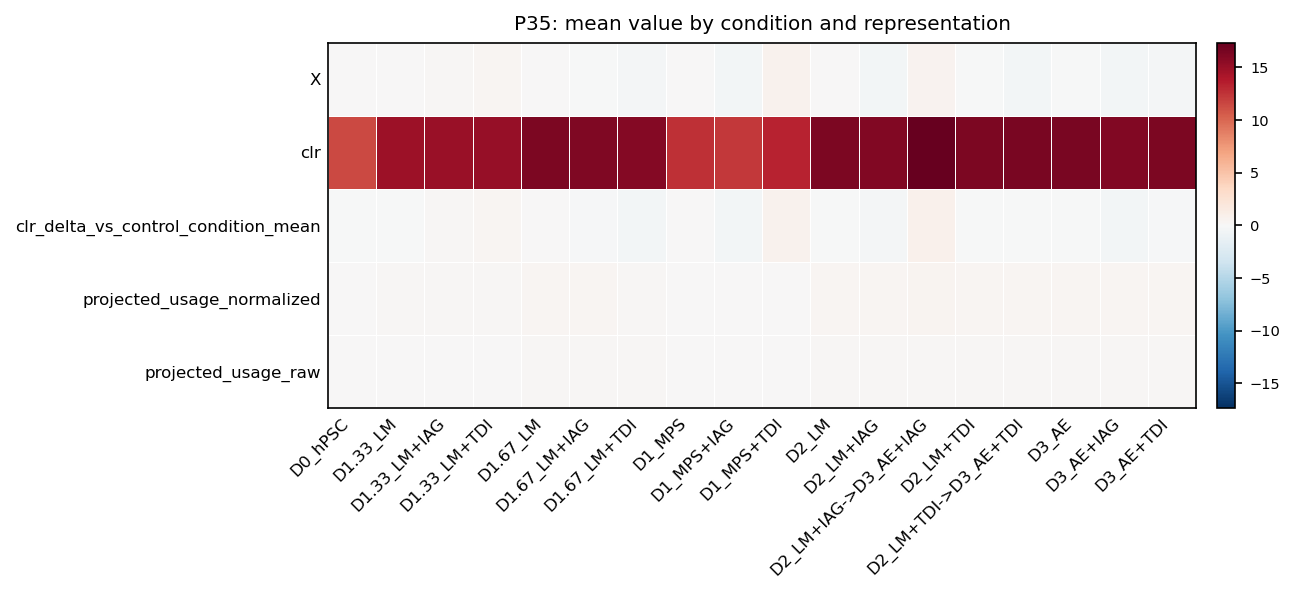


Max abs difference between adata.X and layer['clr_delta_vs_control_condition_mean']: 8.273593

Control sample centering QC; should be near zero if file is centered correctly:


,max_abs_program_mean,mean_abs_program_mean
sample_name,,
D2_LM_rep3,0.000028,1.465122e-06
D0_hPSC_rep1,0.000025,1.885179e-06
D1.67_LM_rep3,0.000025,1.373098e-06
D2_LM_rep2,0.000025,1.624147e-06
D1.33_LM_rep2,0.000022,1.650795e-06
D1_MPS_rep1,0.000019,1.527457e-06
D1.33_LM_rep1,0.000017,1.935096e-06
D0_hPSC_rep3,0.000017,2.544791e-06
D3_AE_rep3,0.000017,1.611901e-06



Control condition means for P35:


,P35
condition,
D0_hPSC,6.654914e-07
D1.33_LM,8.435840e-07
D1.67_LM,2.423414e-07
D1_MPS,3.077426e-06
D2_LM,1.455854e-06
D3_AE,-7.355395e-06



P35 correlations with QC metrics:


...


Reading spectra:
/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50.gene_spectra_tpm.k_50.dt_0_2.txt

Top 50 P35-specific genes by weight fraction:


,gene,P35_weight,P35_specificity,total_weight_across_programs
726,AREG,490.515320,1.000000,490.515320
3957,ENSG00000222032,196.963040,1.000000,196.963040
2570,COL12A1,1100.663000,0.983774,1118.816658
9117,LTBP2,608.050300,0.922872,658.867545
12337,PTPRN,156.396470,0.884072,176.904760
8972,LOX,155.546140,0.849101,183.189260
11636,PLAT,895.424130,0.848296,1055.555625
15397,TM4SF1,301.499820,0.820501,367.458258
16680,XIRP1,75.320870,0.814978,92.420771
15788,TRAF1,209.017610,0.813465,256.947412



Optional marker expression check from full projected AnnData:
/scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad
Marker genes to test: ['AREG', 'ENSG00000222032', 'COL12A1', 'LTBP2', 'PTPRN', 'LOX', 'PLAT', 'TM4SF1', 'XIRP1', 'TRAF1', 'MICAL2', 'EGR3', 'NT5E', 'MLPH', 'CDKN2A', 'SLITRK6', 'EGFR', 'SERPINE1', 'FBXO32', 'SRPX2', 'THBS1', 'PDLIM3', 'STMN2', 'CDKN2B', 'COL6A3']
Present marker genes: ['AREG', 'ENSG00000222032', 'COL12A1', 'LTBP2', 'PTPRN', 'LOX', 'PLAT', 'TM4SF1', 'XIRP1', 'TRAF1', 'MICAL2', 'EGR3', 'NT5E', 'MLPH', 'CDKN2A', 'SLITRK6', 'EGFR', 'SERPINE1', 'FBXO32', 'SRPX2', 'THBS1', 'PDLIM3', 'STMN2', 'CDKN2B', 'COL6A3']
Missing marker genes: []

P35-specific marker expression by condition:


condition,D0_hPSC,D1.33_LM,D1.33_LM+IAG,D1.33_LM+TDI,D1.67_LM,D1.67_LM+IAG,D1.67_LM+TDI,D1_MPS,D1_MPS+IAG,D1_MPS+TDI,D2_LM,D2_LM+IAG,D2_LM+IAG->D3_AE+IAG,D2_LM+TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,D3_AE+IAG,D3_AE+TDI
AREG,0.000560,0.005129,0.001737,0.006951,0.023758,0.028778,0.000000,0.001737,0.005453,0.010311,0.002594,0.003707,0.000000,0.000951,0.001578,0.000000,0.009078,0.001549
ENSG00000222032,0.000343,0.000000,0.000011,0.001222,0.000000,0.001555,0.000009,0.000000,0.000010,0.001889,0.002686,0.004734,0.003538,0.000109,0.003229,0.010088,0.009623,0.001374
COL12A1,0.092575,0.046273,0.038445,0.075139,0.022547,0.015301,0.049875,0.057946,0.024873,0.049017,0.011924,0.012685,0.011909,0.127998,0.398660,0.084474,0.065557,0.672035
LTBP2,0.040828,0.014997,0.025677,0.027479,0.083547,0.052378,0.059494,0.014027,0.016022,0.032632,0.124862,0.103016,0.221679,0.166658,0.066179,0.207116,0.213657,0.109565
PTPRN,0.051561,0.105204,0.082880,0.056012,0.122860,0.174340,0.149855,0.057104,0.038034,0.063397,0.145493,0.194111,0.010190,0.239805,0.143351,0.023319,0.035015,0.038657
LOX,0.030654,0.034235,0.031921,0.045478,0.006559,0.017340,0.079516,0.001262,0.002188,0.024308,0.012552,0.006608,0.000000,0.089647,0.066525,0.005262,0.015582,0.024891
PLAT,0.266254,0.119275,0.084985,0.102124,0.413350,0.176261,1.466591,0.096718,0.051109,0.055520,0.390781,0.274269,0.080021,3.155035,0.293265,0.207312,0.111182,0.167180
TM4SF1,0.024426,0.012034,0.015966,0.009111,0.017601,0.016464,0.013379,0.013582,0.019381,0.011593,0.061384,0.058902,0.032610,0.061236,0.052199,0.273988,0.049928,2.053233
XIRP1,0.000769,0.001126,0.002994,0.001720,0.004292,0.016804,0.002482,0.000000,0.000000,0.000000,0.011092,0.013753,0.017137,0.002103,0.020063,0.033049,0.022939,0.010955
TRAF1,0.058774,0.047367,0.053002,0.041921,0.052334,0.041090,0.057005,0.017041,0.023997,0.012028,0.036788,0.037942,0.053898,0.035910,0.053068,0.043019,0.054390,0.043505


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

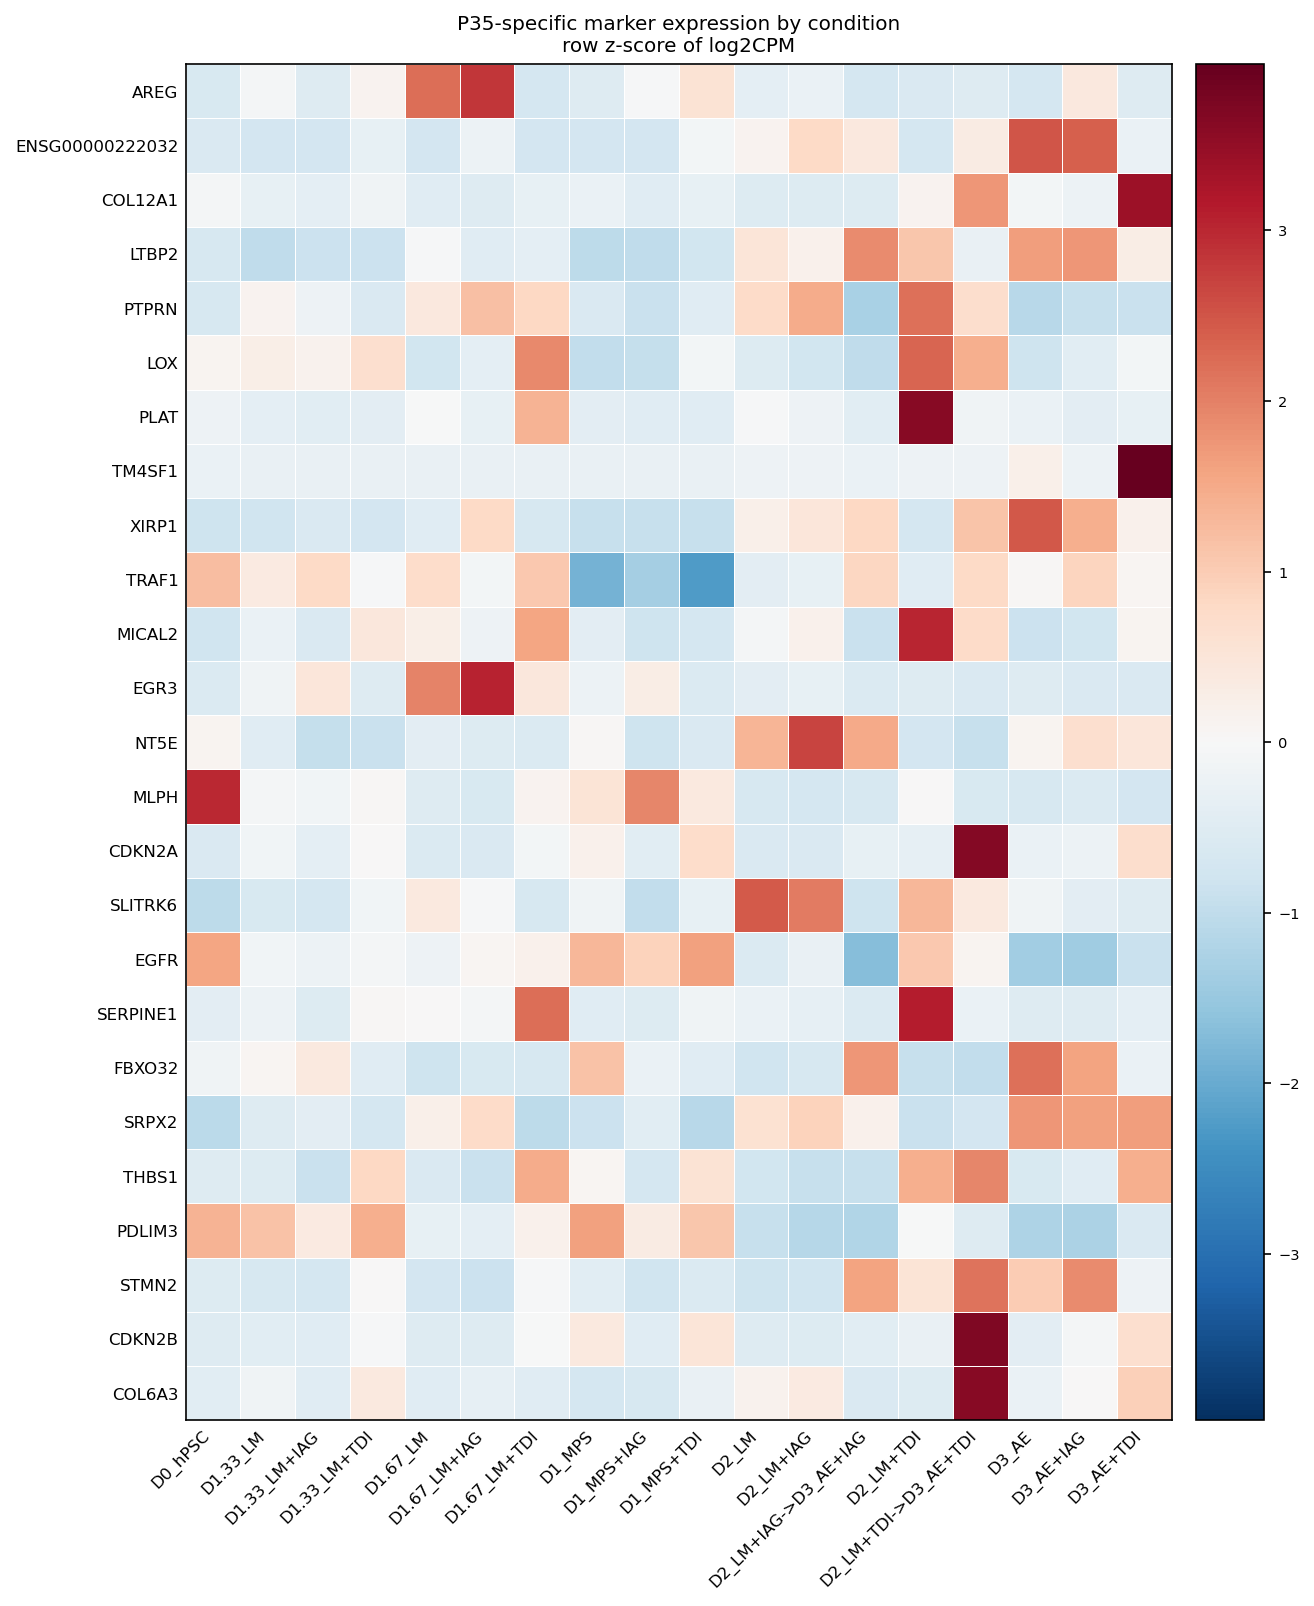


INTERPRETATION CHECKLIST
1. If projected_usage_normalized P35 is high in all conditions:
   → the projection itself is broadly assigning P35 to the query dataset.
2. If clr P35 is high in all conditions:
   → P35 is high relative to the geometric mean of all programs.
3. If X / clr_delta_vs_control_condition_mean controls are ~0:
   → the Hunter control-centered file is working.
4. If P35-specific marker genes are not broadly high:
   → raw P35 projection is probably a transfer/projection artifact.
5. If P35-specific marker genes are broadly high:
   → the time-course dataset may genuinely contain broad P35-like transcriptional signal.

Outputs saved to: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/hunter_cell_x_cnmf_clr/P35_diagnostics
  P35_QC_correlations_all_sources.tsv
  P35_mean_by_condition_all_sources.pdf
  P35_mean_by_condition_all_sources.png
  P35_mean_by_condition_all_sources.svg
  P35_specific_genes_from_spectra.tsv
  P35_specific_marker_expre

In [1]:
# P35 projection sanity/QC cell
# Goal:
#   1. Check whether P35 is high in raw projected usage, raw CLR, or control-centered delta.
#   2. Verify that the Hunter file is using zero-based P0-P49.
#   3. Check whether control-centered CLR deltas are centered at ~0 for control samples.
#   4. Inspect P35 top-loading and P35-specific genes.
#   5. Optionally check P35 marker-gene expression in the full projected AnnData.

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import sparse

warnings.filterwarnings("ignore")

try:
    display
except NameError:
    def display(x):
        print(x if not hasattr(x, "head") else x.head(30).to_string())

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

# ============================================================
# USER SETTINGS
# ============================================================

HUNTER_H5AD = Path(
    "/scratch/users/edtng/20260325_Hippo_timecourse/"
    "perturbseq_cNMF_projection/hunter_cell_x_cnmf_clr/"
    "Hippo_timecourse_cells_x_cNMF_CLR_delta_matched_control.qc_filtered.h5ad"
)

# Full projected time-course AnnData with RNA genes. Used only for optional marker expression check.
FULL_PROJECTED_H5AD = Path(
    "/scratch/users/edtng/20260325_Hippo_timecourse/"
    "perturbseq_cNMF_projection/"
    "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"
)

CNMF_XLSX = Path(
    "/scratch/users/edtng/20260325_Hippo_timecourse/cNMF_50_0_2_032526_6co.xlsx"
)

# Fallback if running from local uploaded file location.
if not CNMF_XLSX.exists() and Path("/mnt/data/cNMF_50_0_2_032526_6co.xlsx").exists():
    CNMF_XLSX = Path("/mnt/data/cNMF_50_0_2_032526_6co.xlsx")

SPECTRA_TPM = Path(
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50."
    "gene_spectra_tpm.k_50.dt_0_2.txt"
)

OUT_DIR = Path(
    "/scratch/users/edtng/20260325_Hippo_timecourse/"
    "perturbseq_cNMF_projection/hunter_cell_x_cnmf_clr/P35_diagnostics"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

PROGRAM_TO_CHECK = "P35"
N_TOP_GENES = 50
N_MARKER_GENES_FOR_EXPRESSION = 25

# For optional marker expression extraction from FULL_PROJECTED_H5AD.
# Use None to read adata.X; set to "mature" / "nascent" / "counts" if you prefer a layer.
GENE_LAYER = None

# ============================================================
# HELPERS
# ============================================================

def to_dense_vector(x):
    if sparse.issparse(x):
        return np.asarray(x.toarray()).ravel()
    return np.asarray(x).ravel()

def to_dense_matrix(x):
    if sparse.issparse(x):
        return x.toarray()
    return np.asarray(x)

def program_num(program):
    m = re.fullmatch(r"P(\d+)", str(program))
    if m is None:
        raise ValueError(f"Program name is not P<number>: {program!r}")
    return int(m.group(1))

def derive_treatment(condition):
    condition = str(condition)
    if "TDI" in condition:
        return "TDI"
    if "IAG" in condition:
        return "IAG"
    return "control"

def parse_sample_name(sample_name):
    sample_name = str(sample_name)
    m = re.match(r"^(.*)_rep(\d+)$", sample_name)
    if m is None:
        return sample_name, np.nan
    return m.group(1), int(m.group(2))

def get_feature_matrix(adata, source):
    if source == "X":
        return to_dense_matrix(adata.X)
    if source not in adata.layers:
        raise KeyError(f"{source!r} not found in adata.layers. Available: {list(adata.layers.keys())}")
    return to_dense_matrix(adata.layers[source])

def get_program_vector(adata, source, program):
    j = list(adata.var_names.astype(str)).index(program)
    if source == "X":
        x = adata.X[:, j]
    else:
        x = adata.layers[source][:, j]
    return to_dense_vector(x)

def zscore_rows(df):
    z = df.sub(df.mean(axis=1), axis=0)
    z = z.div(df.std(axis=1).replace(0, np.nan), axis=0)
    return z.fillna(0)

def plot_heatmap(df, title, out_prefix, cmap="RdBu_r", center_zero=True):
    mat = df.to_numpy(dtype=float)
    n_rows, n_cols = mat.shape
    if center_zero:
        vmax = np.nanmax(np.abs(mat))
        if vmax == 0 or not np.isfinite(vmax):
            vmax = 1
        vmin = -vmax
    else:
        vmin = np.nanmin(mat)
        vmax = np.nanmax(mat)
        if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
            vmin, vmax = 0, 1

    fig_w = max(7, 0.35 * n_cols + 3)
    fig_h = max(4, 0.35 * n_rows + 2)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    im = ax.pcolormesh(
        np.arange(n_cols + 1),
        np.arange(n_rows + 1),
        mat,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        shading="flat",
        linewidth=0.4,
        edgecolors="white",
    )

    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_xticks(np.arange(n_cols) + 0.5)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_xticklabels(df.columns.tolist(), rotation=45, ha="right")
    ax.set_yticklabels(df.index.tolist())
    ax.set_title(title)
    ax.tick_params(length=0)

    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.ax.tick_params(labelsize=7)

    fig.tight_layout()
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(OUT_DIR / f"{out_prefix}.{ext}", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def find_gene_positions(adata, gene):
    gene = str(gene)
    target = gene.upper()

    var_names = pd.Index(adata.var_names.astype(str))
    hits = np.flatnonzero(var_names.str.upper() == target)

    if len(hits) > 0:
        return hits

    for col in ["gene", "gene_symbol", "symbol", "feature_name"]:
        if col not in adata.var.columns:
            continue
        vals = pd.Index(adata.var[col].astype(str))
        hits = np.flatnonzero(vals.str.upper() == target)
        if len(hits) > 0:
            return hits

    return np.array([], dtype=int)

# ============================================================
# 1. LOAD HUNTER CELL x PROGRAM FILE
# ============================================================

print("Loading Hunter file:")
print(HUNTER_H5AD)

adata = sc.read_h5ad(HUNTER_H5AD)

print(adata)
print("layers:", list(adata.layers.keys()))
print("var_names first/last:", adata.var_names[:5].tolist(), adata.var_names[-5:].tolist())

programs = list(adata.var_names.astype(str))
expected_programs = [f"P{i}" for i in range(50)]

if programs != expected_programs:
    print("WARNING: var_names are not exactly P0-P49.")
    print("first 10:", programs[:10])
    print("last 10:", programs[-10:])
else:
    print("Confirmed zero-based P0-P49 var_names.")

if PROGRAM_TO_CHECK not in programs:
    raise ValueError(f"{PROGRAM_TO_CHECK} not present in adata.var_names")

pidx = programs.index(PROGRAM_TO_CHECK)
print(f"{PROGRAM_TO_CHECK} index:", pidx)

# Ensure metadata fields exist or derive them.
if "condition" not in adata.obs.columns or "replicate" not in adata.obs.columns:
    if "sample_name" in adata.obs.columns:
        parsed = adata.obs["sample_name"].astype(str).map(parse_sample_name)
        adata.obs["condition"] = [x[0] for x in parsed]
        adata.obs["replicate"] = [x[1] for x in parsed]

if "treatment" not in adata.obs.columns:
    adata.obs["treatment"] = adata.obs["condition"].map(derive_treatment)

print("conditions:", adata.obs["condition"].astype(str).unique().tolist())

# ============================================================
# 2. COMPARE P35 ACROSS REPRESENTATIONS
# ============================================================

sources_to_check = ["projected_usage_normalized", "projected_usage_raw", "clr", "clr_delta_vs_control_condition_mean", "X"]
existing_sources = []
for src in sources_to_check:
    if src == "X" or src in adata.layers:
        existing_sources.append(src)

print("Sources to check:", existing_sources)

records = []

for src in existing_sources:
    x = get_program_vector(adata, src, PROGRAM_TO_CHECK)

    tmp = adata.obs[["condition", "sample_name", "treatment"]].copy()
    tmp["value"] = x
    tmp["source"] = src

    by_condition = (
        tmp.groupby(["source", "condition"], observed=True)["value"]
        .agg(["mean", "median", "std", "min", "max"])
        .reset_index()
    )
    records.append(by_condition)

p35_source_summary = pd.concat(records, ignore_index=True)
p35_source_summary.to_csv(OUT_DIR / f"{PROGRAM_TO_CHECK}_summary_by_condition_all_sources.tsv", sep="\t", index=False)

print(f"\n{PROGRAM_TO_CHECK} mean by condition and source:")
p35_mean_pivot = p35_source_summary.pivot(index="condition", columns="source", values="mean")
display(p35_mean_pivot)

plot_heatmap(
    p35_mean_pivot.T,
    title=f"{PROGRAM_TO_CHECK}: mean value by condition and representation",
    out_prefix=f"{PROGRAM_TO_CHECK}_mean_by_condition_all_sources",
    center_zero=True,
)

# ============================================================
# 3. VERIFY CONTROL-CENTERED MATRIX BEHAVIOR
# ============================================================

# In the Hunter file, adata.X should equal clr_delta_vs_control_condition_mean.
if "clr_delta_vs_control_condition_mean" in adata.layers:
    X = to_dense_matrix(adata.X)
    L = to_dense_matrix(adata.layers["clr_delta_vs_control_condition_mean"])
    max_diff = np.max(np.abs(X - L))
    print("\nMax abs difference between adata.X and layer['clr_delta_vs_control_condition_mean']:", max_diff)
else:
    X = to_dense_matrix(adata.X)
    print("\nNo layer['clr_delta_vs_control_condition_mean']; using adata.X.")

delta_df = pd.DataFrame(X, index=adata.obs_names.astype(str), columns=programs)
delta_df["condition"] = adata.obs["condition"].astype(str).to_numpy()
delta_df["sample_name"] = adata.obs["sample_name"].astype(str).to_numpy()
delta_df["treatment"] = adata.obs["treatment"].astype(str).to_numpy()

control_sample_means = (
    delta_df.query("treatment == 'control'")
    .groupby("sample_name", observed=True)[programs]
    .mean()
)

control_condition_means = (
    delta_df.query("treatment == 'control'")
    .groupby("condition", observed=True)[programs]
    .mean()
)

control_centering_qc = pd.DataFrame({
    "max_abs_program_mean": control_sample_means.abs().max(axis=1),
    "mean_abs_program_mean": control_sample_means.abs().mean(axis=1),
}).sort_values("max_abs_program_mean", ascending=False)

control_centering_qc.to_csv(OUT_DIR / "control_sample_centering_QC_all_programs.tsv", sep="\t")

print("\nControl sample centering QC; should be near zero if file is centered correctly:")
display(control_centering_qc)

print("\nControl condition means for P35:")
display(control_condition_means[[PROGRAM_TO_CHECK]])

# ============================================================
# 4. CHECK P35 RELATIONSHIP TO QC METRICS
# ============================================================

qc_cols = [
    "total_counts",
    "n_genes_by_counts",
    "pct_counts_mt",
    "pct_counts_ribo",
    "guide_umi_counts",
    "guides_per_cell",
]

qc_records = []

for src in existing_sources:
    x = get_program_vector(adata, src, PROGRAM_TO_CHECK)

    for qc in qc_cols:
        if qc not in adata.obs.columns:
            continue

        y = pd.to_numeric(adata.obs[qc], errors="coerce").to_numpy()
        valid = np.isfinite(x) & np.isfinite(y)

        if valid.sum() > 10:
            corr = np.corrcoef(x[valid], y[valid])[0, 1]
        else:
            corr = np.nan

        qc_records.append({
            "program": PROGRAM_TO_CHECK,
            "source": src,
            "qc_metric": qc,
            "pearson_corr": corr,
            "n_cells": int(valid.sum()),
        })

qc_corr_df = pd.DataFrame(qc_records).sort_values("pearson_corr", key=lambda s: s.abs(), ascending=False)
qc_corr_df.to_csv(OUT_DIR / f"{PROGRAM_TO_CHECK}_QC_correlations_all_sources.tsv", sep="\t", index=False)

print(f"\n{PROGRAM_TO_CHECK} correlations with QC metrics:")
display(qc_corr_df)

# ============================================================
# 5. INSPECT P35 TOP LOADING GENES FROM WORKBOOK
# ============================================================

if CNMF_XLSX.exists():
    print("\nReading Program Loadings from:")
    print(CNMF_XLSX)

    loadings = pd.read_excel(CNMF_XLSX, sheet_name="Program Loadings")
    loadings = loadings.rename(columns={c: str(c).strip() for c in loadings.columns})

    if {"Program", "Rank", "Gene"}.issubset(set(loadings.columns)):
        loadings["program"] = "P" + loadings["Program"].astype(int).astype(str)
        p35_loadings = (
            loadings.query("program == @PROGRAM_TO_CHECK")
            .sort_values("Rank")
            .head(N_TOP_GENES)
            .copy()
        )
        p35_loadings.to_csv(OUT_DIR / f"{PROGRAM_TO_CHECK}_top{N_TOP_GENES}_loading_genes_from_workbook.tsv", sep="\t", index=False)

        print(f"\nTop {N_TOP_GENES} loading genes for {PROGRAM_TO_CHECK}:")
        display(p35_loadings)
    else:
        print("Workbook Program Loadings sheet missing expected columns: Program, Rank, Gene")
        p35_loadings = None
else:
    print("\nCNMF workbook not found, skipping workbook top-loading gene check.")
    p35_loadings = None

# ============================================================
# 6. COMPUTE P35-SPECIFIC GENES FROM SPECTRA
# ============================================================

if SPECTRA_TPM.exists():
    print("\nReading spectra:")
    print(SPECTRA_TPM)

    W = pd.read_csv(SPECTRA_TPM, sep="\t", index_col=0)
    W.index = W.index.astype(str)

    # Relabel source 1..50 to P0..P49 when appropriate.
    try:
        src_ids = [int(float(x)) for x in W.index]
        if src_ids == list(range(1, W.shape[0] + 1)):
            W.index = [f"P{i}" for i in range(W.shape[0])]
        elif src_ids == list(range(W.shape[0])):
            W.index = [f"P{i}" for i in src_ids]
        else:
            print("WARNING: spectra row names are not simple 0- or 1-based program IDs.")
    except Exception:
        print("WARNING: could not parse spectra row names as integers.")

    if PROGRAM_TO_CHECK not in W.index:
        raise ValueError(f"{PROGRAM_TO_CHECK} not found in spectra rows: {W.index[:10].tolist()}")

    W = W.apply(pd.to_numeric, errors="coerce").fillna(0)
    W[W < 0] = 0

    gene_total = W.sum(axis=0).replace(0, np.nan)
    p35_specificity = W.loc[PROGRAM_TO_CHECK] / gene_total

    p35_specific = pd.DataFrame({
        "gene": W.columns.astype(str),
        f"{PROGRAM_TO_CHECK}_weight": W.loc[PROGRAM_TO_CHECK].to_numpy(),
        f"{PROGRAM_TO_CHECK}_specificity": p35_specificity.to_numpy(),
        "total_weight_across_programs": gene_total.to_numpy(),
    }).sort_values(
        [f"{PROGRAM_TO_CHECK}_specificity", f"{PROGRAM_TO_CHECK}_weight"],
        ascending=False,
    )

    p35_specific.to_csv(OUT_DIR / f"{PROGRAM_TO_CHECK}_specific_genes_from_spectra.tsv", sep="\t", index=False)

    print(f"\nTop {N_TOP_GENES} {PROGRAM_TO_CHECK}-specific genes by weight fraction:")
    display(p35_specific.head(N_TOP_GENES))
else:
    print("\nSpectra file not found, skipping P35-specific gene calculation.")
    p35_specific = None

# ============================================================
# 7. OPTIONAL: CHECK P35-SPECIFIC MARKER GENE EXPRESSION IN FULL RNA H5AD
# ============================================================

if FULL_PROJECTED_H5AD.exists() and p35_specific is not None:
    print("\nOptional marker expression check from full projected AnnData:")
    print(FULL_PROJECTED_H5AD)

    marker_genes = p35_specific["gene"].head(N_MARKER_GENES_FOR_EXPRESSION).astype(str).tolist()
    print("Marker genes to test:", marker_genes)

    adata_full = sc.read_h5ad(FULL_PROJECTED_H5AD, backed="r")

    # Align to cells in Hunter file.
    full_cells = pd.Index(adata_full.obs_names.astype(str))
    hunter_cells = pd.Index(adata.obs_names.astype(str))

    row_pos = full_cells.get_indexer(hunter_cells)

    if (row_pos < 0).any():
        missing = hunter_cells[row_pos < 0][:10].tolist()
        print("Some Hunter cells are missing in full AnnData. Skipping expression check. Examples:", missing)
    else:
        # Backed fancy indexing works safest with sorted positions.
        row_sort = np.argsort(row_pos)
        sorted_rows = row_pos[row_sort]
        inverse_sort = np.argsort(row_sort)

        # total_counts for CPM normalization.
        if "total_counts" in adata_full.obs.columns:
            lib_size_sorted = pd.to_numeric(
                adata_full.obs.iloc[sorted_rows]["total_counts"],
                errors="coerce",
            ).to_numpy()
            lib_size = lib_size_sorted[inverse_sort]
        else:
            lib_size = None
            print("total_counts column not found; using log1p raw expression instead of log2CPM.")

        expr_cols = []
        present_genes = []
        missing_genes = []

        for gene in marker_genes:
            gene_pos = find_gene_positions(adata_full, gene)

            if len(gene_pos) == 0:
                missing_genes.append(gene)
                continue

            gene_pos = np.sort(gene_pos)

            if GENE_LAYER is None:
                sub = adata_full[sorted_rows, gene_pos].to_memory()
                x = sub.X
            else:
                if GENE_LAYER not in adata_full.layers:
                    raise KeyError(f"Layer {GENE_LAYER!r} not found in full AnnData.")
                sub = adata_full[sorted_rows, gene_pos].to_memory()
                x = sub.layers[GENE_LAYER]

            if sparse.issparse(x):
                vals_sorted = np.asarray(x.sum(axis=1)).ravel()
            else:
                vals_sorted = np.asarray(x).sum(axis=1).ravel()

            vals = vals_sorted[inverse_sort]

            if lib_size is not None:
                vals = np.log2((vals / np.maximum(lib_size, 1)) * 1e6 + 1)
            else:
                vals = np.log1p(vals)

            expr_cols.append(vals.astype(np.float32))
            present_genes.append(gene)

        print("Present marker genes:", present_genes)
        print("Missing marker genes:", missing_genes)

        if present_genes:
            expr = np.vstack(expr_cols).T
            expr_df = pd.DataFrame(expr, index=adata.obs_names.astype(str), columns=present_genes)
            expr_df["condition"] = adata.obs["condition"].astype(str).to_numpy()
            expr_df["sample_name"] = adata.obs["sample_name"].astype(str).to_numpy()

            # Mean expression by condition.
            expr_by_condition = (
                expr_df.groupby("condition", observed=True)[present_genes]
                .mean()
                .T
            )

            expr_by_sample = (
                expr_df.groupby("sample_name", observed=True)[present_genes]
                .mean()
                .T
            )

            expr_by_condition.to_csv(OUT_DIR / f"{PROGRAM_TO_CHECK}_specific_marker_expression_by_condition.tsv", sep="\t")
            expr_by_sample.to_csv(OUT_DIR / f"{PROGRAM_TO_CHECK}_specific_marker_expression_by_sample.tsv", sep="\t")

            print(f"\n{PROGRAM_TO_CHECK}-specific marker expression by condition:")
            display(expr_by_condition)

            expr_by_condition_z = zscore_rows(expr_by_condition)

            plot_heatmap(
                expr_by_condition_z,
                title=f"{PROGRAM_TO_CHECK}-specific marker expression by condition\nrow z-score of log2CPM",
                out_prefix=f"{PROGRAM_TO_CHECK}_specific_marker_expression_by_condition_zscore",
                center_zero=True,
            )

    adata_full.file.close()

else:
    print("\nSkipping optional marker expression check.")
    print("FULL_PROJECTED_H5AD exists:", FULL_PROJECTED_H5AD.exists())
    print("p35_specific available:", p35_specific is not None)

# ============================================================
# 8. SHORT INTERPRETATION HELP
# ============================================================

print("\nINTERPRETATION CHECKLIST")
print("1. If projected_usage_normalized P35 is high in all conditions:")
print("   → the projection itself is broadly assigning P35 to the query dataset.")
print("2. If clr P35 is high in all conditions:")
print("   → P35 is high relative to the geometric mean of all programs.")
print("3. If X / clr_delta_vs_control_condition_mean controls are ~0:")
print("   → the Hunter control-centered file is working.")
print("4. If P35-specific marker genes are not broadly high:")
print("   → raw P35 projection is probably a transfer/projection artifact.")
print("5. If P35-specific marker genes are broadly high:")
print("   → the time-course dataset may genuinely contain broad P35-like transcriptional signal.")
print("\nOutputs saved to:", OUT_DIR)
for p in sorted(OUT_DIR.glob("*")):
    print(" ", p.name)